# Classification Comparison and Clustering Exploration on Medical Data

**Datasets: diabetes and heart-statlog**

**Team members:**

- **Team leader: CHEN Sitao (3163293)**
- HU Yining (3162495)
- QU Yide (3352662)
- Wu Fei (3162926)
- MAI Zixi (3162873)

## 1. Project Overview

This project uses two medical datasets, diabetes and heart-statlog, in three experiments: two examine **how preprocessing and classifier choice affect classification performance**, and one explores the clustering structure of diabetes.

- **Experiment 1:** Compare **one classifier**, on **one dataset**, **with and without standardization**.
- **Experiment 2:** Compare **four classifiers** under **two evaluation protocols** on **two datasets**.
- **Experiment 3:** Explore **clusters in one dataset**, then examine their **feature profiles** and **class-label distributions**.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from scipy.io import arff
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             roc_curve, silhouette_score)
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display, Markdown

## 2. Data Description and Exploratory Analysis

### 2.1 Data Sources and Attribute Descriptions

Both **diabetes.arff** and **heart-statlog.arff** were obtained from the **learning materials provided on the course Moodle site**. The following pages provide additional information about the datasets:

- **heart-statlog:** [Official UCI dataset page](https://archive.ics.uci.edu/dataset/145/statlog+heart)
- **diabetes:** [Public copy on OpenML](https://www.openml.org/search?type=data&id=37)

Project files:

```text
root/
├── diabetes-heart-statlog-experiments_CN.ipynb
├── diabetes-heart-statlog-experiments_EN.ipynb
├── diabetes.arff
└── heart-statlog.arff
```

We first read the comments in the two ARFF files to understand what the data represent.


In [2]:
DIABETES_PATH = Path('diabetes.arff')
HEART_STATLOG_PATH = Path('heart-statlog.arff')

# Open the ARFF files as text.
# Prepare the descriptive text.
# Display selected file comments.
for path, start_marker in [
    (DIABETES_PATH, '% 4. Relevant Information:'),
    (HEART_STATLOG_PATH, '% This database contains'),
]:
    # Read only the descriptions and attribute declarations before the data section.
    header = path.read_text(encoding='utf-8').split('@data', 1)[0]

    # Start at the descriptive section selected for display.
    selected = header[header.index(start_marker):]

    # Remove comment markers and empty comment lines; preserve the original text and indentation.
    description = '\n'.join(
        line.removeprefix('%').removeprefix(' ').rstrip()
        for line in selected.splitlines()
        if line.strip() != '%'
    )

    display(Markdown(
        f'#### {path.name}\n\n```text\n{description.strip()}\n```'
    ))

#### diabetes.arff

```text
4. Relevant Information:
      Several constraints were placed on the selection of these instances from
      a larger database.  In particular, all patients here are females at
      least 21 years old of Pima Indian heritage.  ADAP is an adaptive learning
      routine that generates and executes digital analogs of perceptron-like
      devices.  It is a unique algorithm; see the paper for details.
5. Number of Instances: 768
6. Number of Attributes: 8 plus class
7. For Each Attribute: (all numeric-valued)
   1. Number of times pregnant
   2. Plasma glucose concentration a 2 hours in an oral glucose tolerance test
   3. Diastolic blood pressure (mm Hg)
   4. Triceps skin fold thickness (mm)
   5. 2-Hour serum insulin (mu U/ml)
   6. Body mass index (weight in kg/(height in m)^2)
   7. Diabetes pedigree function
   8. Age (years)
   9. Class variable (0 or 1)
8. Missing Attribute Values: None
9. Class Distribution: (class value 1 is interpreted as "tested positive for
   diabetes")
   Class Value  Number of instances
   0            500
   1            268
10. Brief statistical analysis:
    Attribute number:    Mean:   Standard Deviation:
    1.                     3.8     3.4
    2.                   120.9    32.0
    3.                    69.1    19.4
    4.                    20.5    16.0
    5.                    79.8   115.2
    6.                    32.0     7.9
    7.                     0.5     0.3
    8.                    33.2    11.8
Relabeled values in attribute 'class'
   From: 0                       To: tested_negative
   From: 1                       To: tested_positive
@relation pima_diabetes
@attribute 'preg' real
@attribute 'plas' real
@attribute 'pres' real
@attribute 'skin' real
@attribute 'insu' real
@attribute 'mass' real
@attribute 'pedi' real
@attribute 'age' real
@attribute 'class' { tested_negative, tested_positive}
```

#### heart-statlog.arff

```text
This database contains 13 attributes (which have been extracted from
a larger set of 75)
Attribute Information:
------------------------
      -- 1. age
      -- 2. sex
      -- 3. chest pain type  (4 values)
      -- 4. resting blood pressure
      -- 5. serum cholestoral in mg/dl
      -- 6. fasting blood sugar > 120 mg/dl
      -- 7. resting electrocardiographic results  (values 0,1,2)
      -- 8. maximum heart rate achieved
      -- 9. exercise induced angina
      -- 10. oldpeak = ST depression induced by exercise relative to rest
      -- 11. the slope of the peak exercise ST segment
      -- 12. number of major vessels (0-3) colored by flourosopy
      -- 13.  thal: 3 = normal; 6 = fixed defect; 7 = reversable defect
Attributes types
-----------------
Real: 1,4,5,8,10,12
Ordered:11,
Binary: 2,6,9
Nominal:7,3,13
Variable to be predicted
------------------------
Absence (1) or presence (2) of heart disease
Cost Matrix
         abse  pres
absence   0     1
presence  5     0
where the rows represent the true values and the columns the predicted.
No missing values.
270 observations
Relabeled values in attribute class
   From: 1                       To: absent
   From: 2                       To: present
@relation heart-statlog
@attribute age real
@attribute sex real
@attribute chest real
@attribute resting_blood_pressure real
@attribute serum_cholestoral real
@attribute fasting_blood_sugar real
@attribute resting_electrocardiographic_results real
@attribute maximum_heart_rate_achieved real
@attribute exercise_induced_angina real
@attribute oldpeak real
@attribute slope real
@attribute number_of_major_vessels real
@attribute thal real
@attribute class { absent, present}
```

### 2.2 Dataset Characteristics and Experimental Plan

#### 2.2.1 Dataset Characteristics

The file descriptions indicate that:

- Both datasets concern binary classification in a medical context.
- diabetes has eight numeric features. heart-statlog has 13 features, including numeric and categorical features. Although all heart-statlog input attributes are declared as `real` in the ARFF file, some values are category codes.
- The numeric features in diabetes have different scales, making the dataset suitable for studying the effect of standardization.
- Both descriptions state that there are no missing values. However, the recorded values still need to be checked for unmarked missing values.

#### 2.2.2 Attribute Descriptions

##### Input Features

**diabetes: eight input features**

| Attribute | Description | Semantic type |
|---|---|---|
| `preg` | Number of pregnancies | Numeric |
| `plas` | Plasma glucose concentration | Numeric |
| `pres` | Diastolic blood pressure | Numeric |
| `skin` | Skinfold thickness | Numeric |
| `insu` | Serum insulin level | Numeric |
| `mass` | Body mass index (BMI) | Numeric |
| `pedi` | Diabetes pedigree function | Numeric |
| `age` | Age | Numeric |

**heart-statlog: 13 input features**

| Attribute | Description | Semantic type |
|---|---|---|
| `age` | Age | Numeric |
| `resting_blood_pressure` | Resting blood pressure | Numeric |
| `serum_cholestoral` | Serum cholesterol | Numeric |
| `maximum_heart_rate_achieved` | Maximum heart rate achieved | Numeric |
| `oldpeak` | ST depression induced by exercise relative to rest | Numeric |
| `number_of_major_vessels` | Number of major vessels visualized by fluoroscopy | Numeric |
| `sex` | Sex | Categorical |
| `chest` | Chest pain type | Categorical |
| `fasting_blood_sugar` | Whether fasting blood sugar exceeds 120 mg/dL | Categorical |
| `resting_electrocardiographic_results` | Resting electrocardiographic results | Categorical |
| `exercise_induced_angina` | Exercise-induced angina | Categorical |
| `slope` | Slope of the peak exercise ST segment | Categorical |
| `thal` | Test-result category | Categorical |

##### Class Labels

Both datasets store the class label in the `class` column. The original values are:

- **diabetes:** `tested_negative` denotes a negative diabetes test result; `tested_positive` denotes a positive result.
- **heart-statlog:** `absent` denotes absence of heart disease (negative); `present` denotes presence of heart disease (positive).

Throughout the experiments, the negative class is encoded as `False` and the positive class as `True`.

#### 2.2.3 Initial Experimental Plan

##### Models

- Supervised models:

  - **Logistic regression:** A linear classification baseline.
  - **Decision tree:** A single-tree classifier.
  - **Random forest:** An ensemble of trees, compared with the single decision tree.
  - **k-nearest neighbors (k-NN):** A distance-based classifier used to investigate standardization.

- Unsupervised model:

  - **K-means:** Group samples by their features, then examine cluster differences and separation.

##### Evaluation

- Supervised models:

  - **Percentage split:** Use a stratified split with 80% of samples for training and 20% for testing; evaluate the fitted model on the test set.
  - **10-fold cross-validation (CV):** Use ten stratified folds. Train on nine folds and test on the remaining fold in each round, then summarize the ten rounds.
  - Classifiers use the same splits within each dataset and evaluation protocol.

- Unsupervised model:

  - Fit a clustering model for each candidate **number of clusters**. Compare the **mean silhouette scores**, select the candidate with the highest score, and examine its **cluster feature profiles** and **class-label distributions**.

##### Preprocessing

- Categorical features:

  - **One-hot encoding:** Represent categories using binary indicator columns.

- Numeric features:

  - **Marking unrecorded missing values:** Use attribute meanings to identify values that represent missing observations and replace them with `NaN`.
  - **Mean imputation:** Replace missing values with the mean of the corresponding feature.
  - **Standardization:** Enable or disable standardization according to the experiment.

We next inspect the **dataset summary table** and **feature distribution plots** to check the data and establish the preprocessing rules.

In [3]:
# Dataset names.
DIABETES = 'pima_diabetes'
HEART_STATLOG = 'heart-statlog'

# Categorical feature names; the meanings of their category codes need further checking.
HEART_CATEGORICAL_FEATURES = [
    'sex',
    'chest',
    'fasting_blood_sugar',
    'resting_electrocardiographic_results',
    'exercise_induced_angina',
    'slope',
    'thal',
]

# Original negative and positive labels for each dataset.
LABELS = {
    DIABETES: ('tested_negative', 'tested_positive'),
    HEART_STATLOG: ('absent', 'present')
}

# Shared experimental settings.
SEED, TEST_SIZE, N_FOLDS, THRESHOLD = 42, 0.2, 10, 0.5

# Models used in the experiments.
LOGISTIC = LogisticRegression(
    C=1.0,
    solver='lbfgs',
    max_iter=2000,
    random_state=SEED
)
TREE = DecisionTreeClassifier(
    criterion='gini',
    max_depth=None,
    min_samples_leaf=1,
    random_state=SEED
)
FOREST = RandomForestClassifier(
    n_estimators=100,
    criterion='gini',
    max_depth=None,
    min_samples_leaf=1,
    max_features='sqrt',
    random_state=SEED,
    n_jobs=1
)
KNN = KNeighborsClassifier(
    n_neighbors=5,
    weights='uniform',
    metric='minkowski',
    p=2
)

class Dataset:
    """Store a project's features, labels, and split-generation methods.

    :ivar name: Dataset name declared in the ARFF file.
    :ivar X: Input feature DataFrame, excluding the class column.
    :ivar y: Boolean labels; True is positive and False is negative.
    :ivar numeric: Numeric feature names.
    :ivar categorical: Categorical feature names.
    """
    def __init__(self, arff_path):
        """Load an ARFF file and identify its features, labels, and feature types.

        :param arff_path: Path to the ARFF file.
        :return: None; data are stored as instance attributes.
        :raises ValueError: The dataset is not one of the two supported datasets.
        """

        records, metadata = arff.loadarff(arff_path)
        if metadata.name not in [DIABETES, HEART_STATLOG]:
            raise ValueError(f'Unsupported dataset: {metadata.name}')
        raw = pd.DataFrame(records)
        raw['class'] = raw['class'].str.decode('utf-8')

        self.name = metadata.name
        _, positive = LABELS[self.name]
        self.X = raw.drop(columns='class')
        self.y = raw['class'].eq(positive)
        self.categorical = [c for c in self.X.columns if c in HEART_CATEGORICAL_FEATURES]
        self.numeric = [c for c in self.X.columns if c not in HEART_CATEGORICAL_FEATURES]

    def identify_missing_values(self, *feature_names):
        """Replace zeros in selected features with NaN in place.

        :param feature_names: One or more feature names whose zeros represent missing values.
        :return: None; modifies the current object's X.
        """
        feature_names = list(feature_names)
        self.X[feature_names] = self.X[feature_names].mask(
            self.X[feature_names].eq(0)
        )

    def category_values(self):
        """List observed category codes for one-hot encoding.

        :return: Mapping from feature names to sorted integer codes observed in X.
        """
        return {
            feature: sorted(self.X[feature].astype(int).unique().tolist())
            for feature in self.categorical
        }

    def generate_percentage_split(self):
        """Generate training and test row indices for a stratified percentage split.

        The test proportion is TEST_SIZE and the random seed is SEED.
        Stratification approximately preserves the original class proportions.

        :return: (train, test), two arrays of zero-based row positions.
        """
        positions = np.arange(len(self.X))
        train, test = train_test_split(
            positions,
            test_size=TEST_SIZE,
            stratify=self.y,
            random_state=SEED,
        )
        return train, test

    def generate_10_fold_cv(self):
        """Generate all training and test row indices for stratified cross-validation.

        N_FOLDS specifies the number of folds (10 in this project).
        Samples are shuffled using SEED; each sample is tested exactly once.

        :return: A list of N_FOLDS (train, test) pairs of row-position arrays.
        """
        folds = list(StratifiedKFold(
            n_splits=N_FOLDS,
            shuffle=True,
            random_state=SEED
        ).split(self.X, self.y))
        return folds

    def summary(self):
        """Collect dataset statistics for the summary table.

        :return: Dictionary containing sample and feature counts, numeric and categorical
            feature counts, positive and negative counts, and the positive proportion (0 to 1).
        """
        return {
            'samples': len(self.X),
            'features': self.X.shape[1],
            'numeric': len(self.numeric),
            'categorical': len(self.categorical),
            'positive': int(self.y.sum()),
            'negative': int((~self.y).sum()),
            'ratio': self.y.mean()
        }


In [4]:
# Create the diabetes and heart-statlog Dataset objects.
# Each stores features, labels, and feature types for later analysis and experiments.
diabetes = Dataset(DIABETES_PATH)
heart = Dataset(HEART_STATLOG_PATH)

# Display both dataset summaries in a formatted table.
overview = pd.DataFrame(
    [diabetes.summary(), heart.summary()],
    index=[DIABETES, HEART_STATLOG],
).T
display(
    overview.style
    .format(lambda x: f'{x:.3f}'.rstrip('0').rstrip('.'))
    .set_caption('Overview')
)

,pima_diabetes,heart-statlog
samples,768,270
features,8,13
numeric,8,6
categorical,0,7
positive,268,120
negative,500,150
ratio,0.349,0.444


### 2.3 Feature Distributions

diabetes contains 768 samples and eight **numeric features**. heart-statlog contains 270 samples, with six **numeric features** and seven **categorical features**. The positive-class proportions are approximately 34.9% and 44.4%, respectively; diabetes therefore has a more **imbalanced class distribution**.

The following plots show each feature's distribution: histograms for numeric features and bar charts for categorical features.


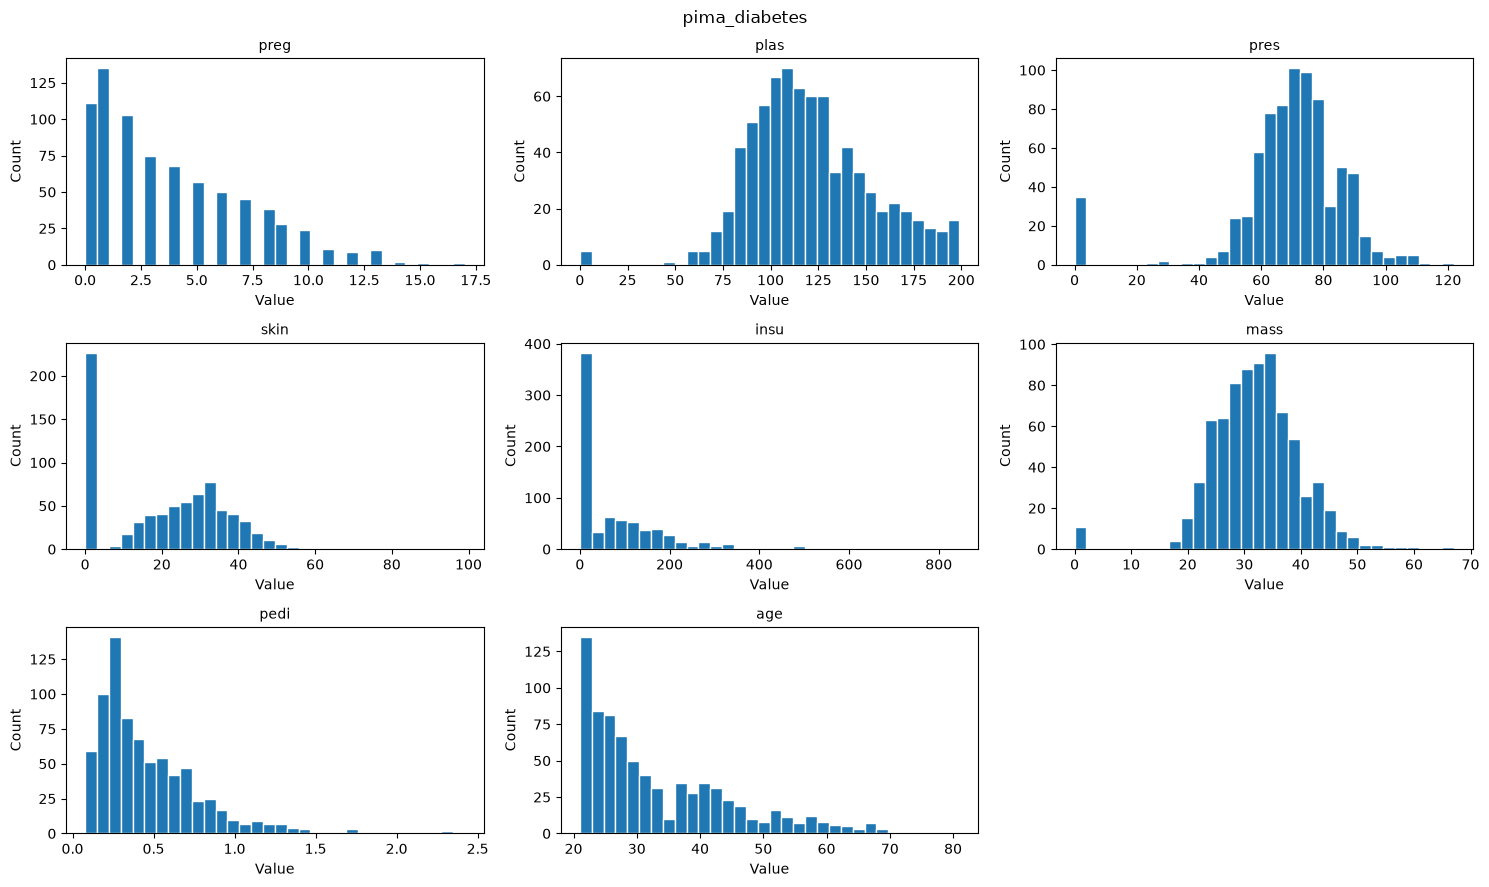

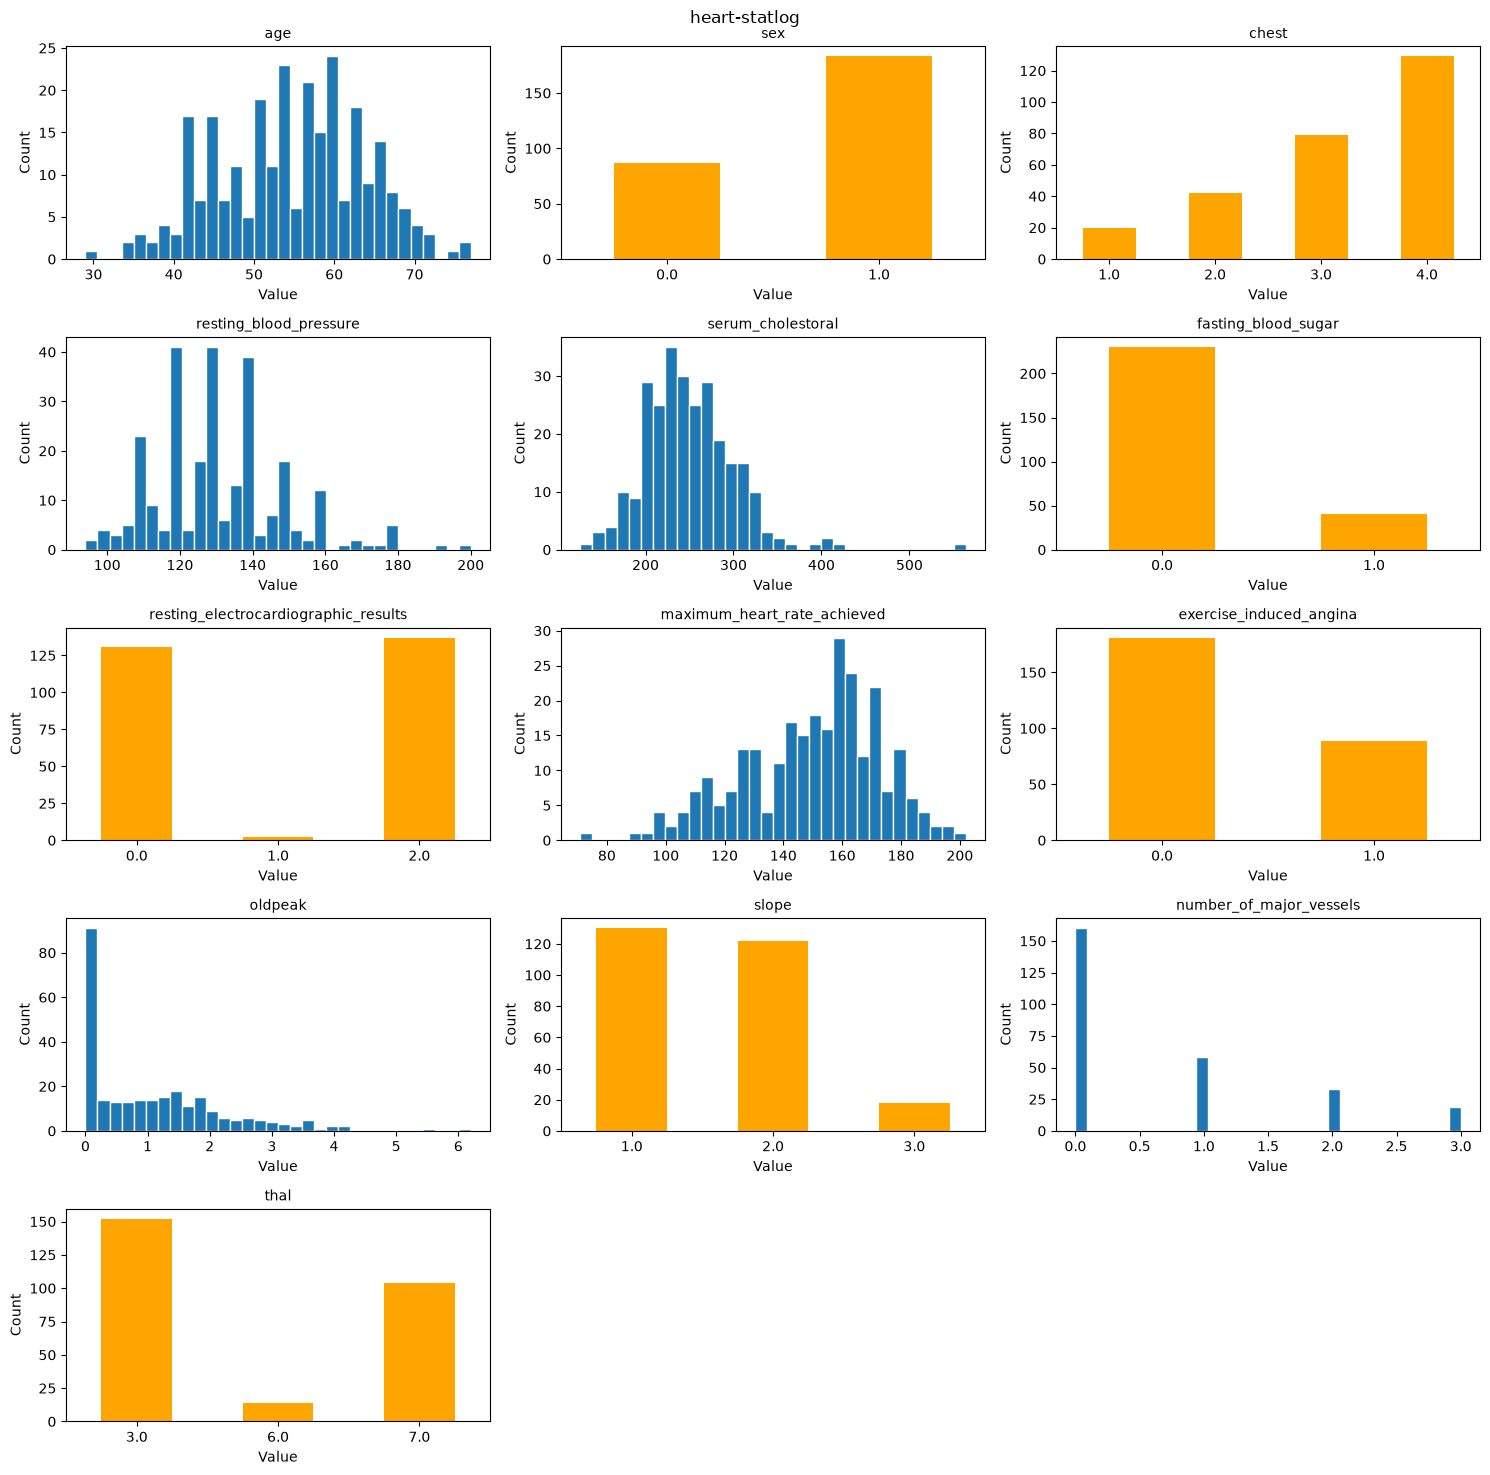

In [5]:
# Plot feature distributions separately for diabetes and heart-statlog.
# Use one figure per dataset and one subplot per feature.
for dataset in [diabetes, heart]:
    # 1. Prepare a figure with three subplots per row.
    n_features = dataset.X.shape[1]
    n_rows = (n_features + 2) // 3

    fig, axes = plt.subplots(
        n_rows, 3,
        figsize=(15, 3 * n_rows),
        squeeze=False,
    )

    # 2. Choose a bar chart or histogram according to the feature type.
    for ax, feature in zip(axes.flat, dataset.X.columns):
        values = dataset.X[feature]

        if feature in dataset.categorical:
            # Categorical feature: display the sample count for each category.
            counts = values.value_counts().sort_index()
            counts.plot.bar(ax=ax, rot=0, color='orange')
        else:
            # Numeric feature: display counts in numeric intervals.
            ax.hist(values, bins=32, edgecolor='white')

        ax.set_title(feature, fontsize=10)
        ax.set_xlabel('Value')
        ax.set_ylabel('Count')

    # 3. Hide unused subplots, set the figure title, and adjust the layout.
    for ax in list(axes.flat)[n_features:]:
        ax.set_visible(False)

    fig.suptitle(dataset.name)
    fig.tight_layout()
    plt.show()


### 2.4 Identifying and Marking Missing Values

The distribution plots show zeros in five diabetes features: glucose (`plas`), diastolic blood pressure (`pres`), skinfold thickness (`skin`), insulin (`insu`), and BMI (`mass`). Based on their meanings, this experiment treats these zeros as **unmarked missing values**.

We first replace zeros in these five columns with `NaN`. During classification experiments, missing values are then imputed using the corresponding feature means from the current training set.

No missing values were found in heart-statlog, so the following outputs describe diabetes only.

#### 2.4.1 Missing-Value Proportions

Calculate the proportion of missing values in each affected feature and output:

- **One bar chart of missing-value proportions.**

#### 2.4.2 Distributions Before and After Marking Missing Values

For each of the five affected features, compare the distributions before and after missing values are marked:

- **Ten histograms**, arranged in five rows and two columns on one figure. The left column shows the original values; the right column shows the values after zeros are marked as missing.


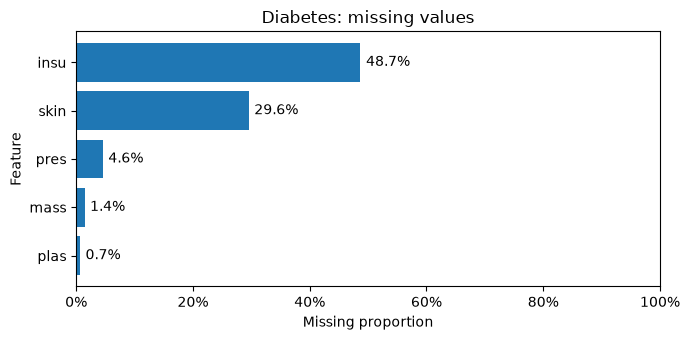

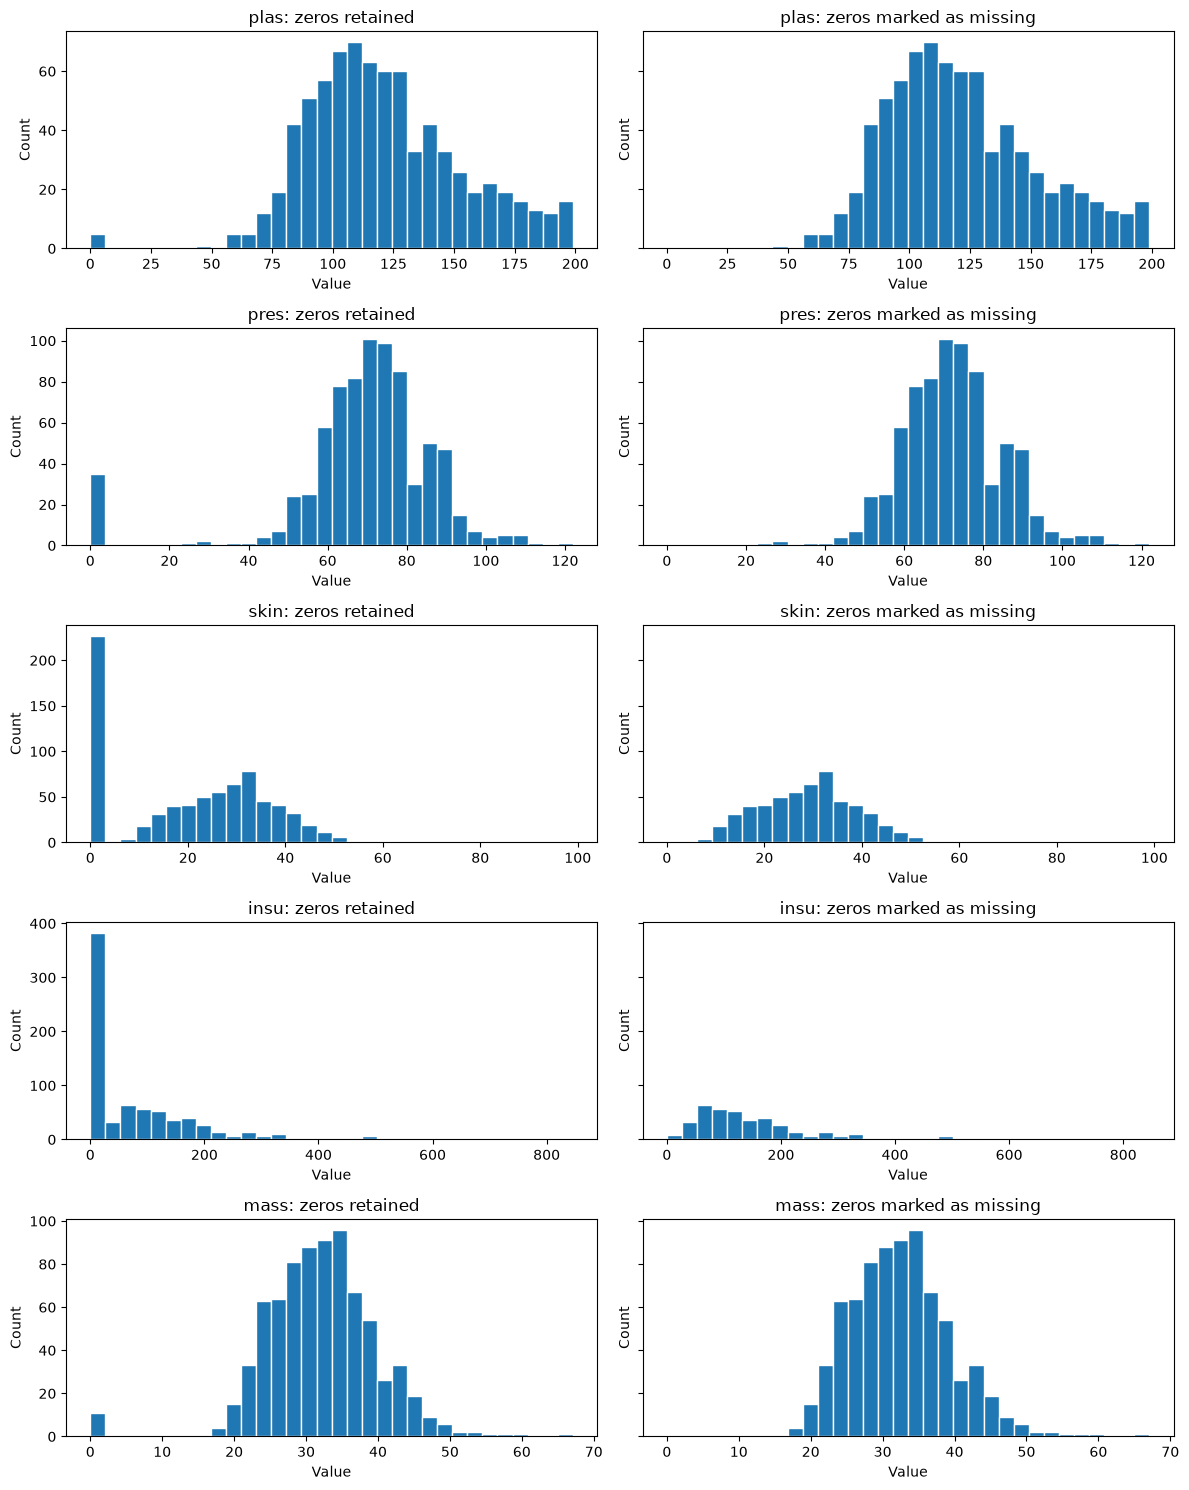

In [6]:
# 1. Mark unrecorded missing values: replace zeros in the five selected columns with NaN.
ZERO_MISSING = ['plas', 'pres', 'skin', 'insu', 'mass']

# Keep the original values for the before-and-after histograms.
before = diabetes.X[ZERO_MISSING].copy()
diabetes.identify_missing_values(*ZERO_MISSING)

# 2. Calculate missing counts / sample count; plot only features with missing values.
missing_ratio = diabetes.X.isna().mean()
missing_ratio = missing_ratio[missing_ratio > 0].sort_values()

fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(missing_ratio.index, missing_ratio.values, color='tab:blue')
ax.bar_label(bars, labels=[f'{ratio:.1%}' for ratio in missing_ratio], padding=4)
ax.set(
    title='Diabetes: missing values',
    xlabel='Missing proportion',
    ylabel='Feature',
    xlim=(0, 1),
)
ax.xaxis.set_major_formatter(PercentFormatter(xmax=1))
plt.tight_layout()
plt.show()

# 3. Compare distributions: one feature per row, original values on the left and marked values on the right.
# Share axis limits within each row; mean imputation is deferred to model training.
fig, axes = plt.subplots(
    len(ZERO_MISSING), 2,
    figsize=(12, 3 * len(ZERO_MISSING)),
    sharex='row',
    sharey='row',
    squeeze=False,
)

for i, feature in enumerate(ZERO_MISSING):
    # Use identical bin edges in each pair so changes reflect missing-value marking.
    bins = np.histogram_bin_edges(before[feature].dropna(), bins=32)

    # Left: retain the original zeros.
    axes[i, 0].hist(
        before[feature].dropna(),
        bins=bins,
        edgecolor='white',
    )
    # Right: exclude zeros marked as NaN; count the remaining observed values.
    axes[i, 1].hist(
        diabetes.X[feature].dropna(),
        bins=bins,
        edgecolor='white',
    )

    axes[i, 0].set_title(f'{feature}: zeros retained')
    axes[i, 1].set_title(f'{feature}: zeros marked as missing')

    for ax in axes[i]:
        ax.set_xlabel('Value')
        ax.set_ylabel('Count')

plt.tight_layout()
plt.show()


### 2.5 Missing-Value Analysis

#### 2.5.1 Observations from the Missing-Value Proportion Chart

Approximately **48.7% of insulin values (`insu`)** and **29.6% of skinfold thickness values (`skin`)** are missing. The missing-value proportions in the other three features are all below 5%.

#### 2.5.2 Observations from the Before-and-After Histograms

After missing values are marked, zeros are excluded from the histograms in the right column. All other observed values remain unchanged.


## 3. Shared Experimental Methods

### 3.1 Data Splits

Generate training and test row indices separately for each dataset:

- Stratified 80%/20% percentage split: one `(train, test)` pair.
- Stratified 10-fold cross-validation: ten `(train, test)` pairs.


In [7]:
# Generate arrays of training and test row indices.
diabetes_train, diabetes_test = diabetes.generate_percentage_split()
diabetes_folds = diabetes.generate_10_fold_cv()

heart_train, heart_test = heart.generate_percentage_split()
heart_folds = heart.generate_10_fold_cv()

The preceding cell saves the **split plans** for both datasets. Each `(train, test)` pair specifies which samples are used for training and which are used for testing.

**Percentage split: one pair of `(train, test)` row-index arrays**

`diabetes_train` and `diabetes_test` store the training and test row indices for diabetes. `heart_train` and `heart_test` store the corresponding indices for heart-statlog.

```text
dataset -> [1 2 3 4 5 6 7 8 9 10]
train   -> [1 2 3 4 5 6 7 8]
test    -> [9 10]

One split: 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟧 🟧
```

**10-fold cross-validation: ten pairs of `(train, test)` row-index arrays**

`diabetes_folds` and `heart_folds` store the ten-fold split plans. Each round uses nine folds for training and one for testing, for ten rounds in total.

```text
folds
├─ Fold  1 (train, test)  🟧 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦
├─ Fold  2 (train, test)  🟦 🟧 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦
├─ Fold  3 (train, test)  🟦 🟦 🟧 🟦 🟦 🟦 🟦 🟦 🟦 🟦
├─ Fold  4 (train, test)  🟦 🟦 🟦 🟧 🟦 🟦 🟦 🟦 🟦 🟦
├─ Fold  5 (train, test)  🟦 🟦 🟦 🟦 🟧 🟦 🟦 🟦 🟦 🟦
├─ Fold  6 (train, test)  🟦 🟦 🟦 🟦 🟦 🟧 🟦 🟦 🟦 🟦
├─ Fold  7 (train, test)  🟦 🟦 🟦 🟦 🟦 🟦 🟧 🟦 🟦 🟦
├─ Fold  8 (train, test)  🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟧 🟦 🟦
├─ Fold  9 (train, test)  🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟧 🟦
└─ Fold 10 (train, test)  🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟦 🟧
```

These are **split plans expressed as sample row indices**. When an experiment runs, the saved indices are used to select the actual training and test samples.

### 3.2 Preprocessing Plan

Zeros representing missing values have already been marked. The remaining preprocessing steps are defined as follows:

- **Numeric features:**

  - **Missing-value imputation:** Mean imputation.
  - **Standardization:** In **Experiment 1**, **whether to standardize** is the experimental variable.

- **Categorical features:**

  - **One-hot encoding:** Convert categories into binary indicator columns.

At this stage, we simply define the preprocessor without applying it to the dataset. Marking missing values can be done once because the rule is based on attribute meanings and **does not require estimated means or standard deviations**. Imputation and standardization, however, **do require these estimates**. Calculating them from the full dataset before classification evaluation would **leak test-set information into training**. So, the preprocessor will be fitted on the current training set during a specific classification workflow.

As for one-hot encoding, it can be applied before the classification workflow or within its preprocessing pipeline. We select the latter approach.

```mermaid
flowchart TD
    A["Shared preprocessing:<br/>mark missing values"] --> S["Define split plans:<br/>save training and test row indices"]
    S --> B["Define remaining preprocessing:<br/>mean imputation, standardization (optional),<br/>one-hot encoding"]
    B --> C["Workflow 1"]
    B --> D["Workflow 2"]
    B --> E["Further workflows..."]
    C --> C1["Apply split plan"] --> C2["Apply preprocessing plan"] --> F["Train model 1"] --> H["Predict and evaluate"]
    D --> D1["Apply split plan"] --> D2["Apply preprocessing plan"] --> G["Train model 2"] --> I["Predict and evaluate"]
```


In [8]:
def make_preprocessor(dataset, standardize=True):
    # Numeric features: mean imputation followed by optional standardization.
    steps = [('impute', SimpleImputer(strategy='mean'))]
    if standardize:
        steps.append(('scale', StandardScaler()))

    # Categorical features: supply category codes in input-column order.
    category_values = dataset.category_values()
    encoder = OneHotEncoder(
        categories=[category_values[c] for c in dataset.categorical]
    )

    # Combine the numeric and categorical transformations.
    return ColumnTransformer([
        ('numeric', Pipeline(steps), dataset.numeric),
        ('categorical', encoder, dataset.categorical),
    ])

### 3.3 Result Storage and Evaluation Metrics

#### 3.3.1 Result Storage

The predictions from one training-and-test round are stored in a `Result` object. Percentage-split evaluation produces **1 `Result`**. In 10-fold cross-validation, a model is trained and tested 10 times, producing **10 `Result` objects**. Each object stores:

- **True labels, `y_test`:** The actual classes of the test samples.
- **Predicted labels, `y_pred`:** The classes assigned by the classifier.
- **Positive-class scores, `scores`:** The classifier's estimated probabilities of the positive class. Higher scores indicate stronger predictions for the positive class.

#### 3.3.2 Metric Calculation

From these predictions, `Result` calculates **five evaluation metrics**, generates a **confusion matrix**, and provides the data needed to plot an **ROC curve**.

The five metrics are:

- **Accuracy:** The proportion of all test samples classified correctly.
- **Precision:** The proportion of predicted positive samples that are actually positive.
- **Recall:** The proportion of actual positive samples identified correctly.
- **F1:** The harmonic mean of precision and recall.
- **ROC-AUC:** The area under the ROC curve. Higher values generally indicate better discrimination.


In [9]:
class Result:
    """Store predictions from one classification fold and provide evaluation data.

    :ivar y_test: True Boolean labels for this test fold.
    :ivar y_pred: Labels obtained by comparing positive-class scores with THRESHOLD.
    :ivar scores: Predicted positive-class probabilities for this test fold.
    """
    def __init__(self, pipeline, X_train, y_train, X_test, y_test):
        """Fit the pipeline, predict the test samples, and store the results.

        :param pipeline: Assembled, unfitted preprocessing and classification pipeline.
        :param X_train: Training feature DataFrame for this fold.
        :param y_train: Corresponding Boolean training labels.
        :param X_test: Test feature DataFrame for this fold.
        :param y_test: Corresponding true Boolean test labels.
        :return: None; stores scores, predicted labels, and true labels.
        """
        pipeline.fit(X_train, y_train)
        positive_column = list(pipeline.classes_).index(True)
        self.scores = pipeline.predict_proba(X_test)[:, positive_column]
        self.y_pred = self.scores >= THRESHOLD
        self.y_test = y_test

    def get_metrics(self):
        """Calculate five classification metrics for this fold.

        :return: pd.Series containing Accuracy, Precision, Recall, F1, and ROC-AUC;
            True is the positive class.
        """
        return pd.Series({
            'Accuracy': accuracy_score(self.y_test, self.y_pred),
            'Precision': precision_score(
                self.y_test, self.y_pred,
                pos_label=True, zero_division=0,
            ),
            'Recall': recall_score(
                self.y_test, self.y_pred,
                pos_label=True, zero_division=0,
            ),
            'F1': f1_score(
                self.y_test, self.y_pred,
                pos_label=True, zero_division=0,
            ),
            'ROC-AUC': roc_auc_score(self.y_test, self.scores),
        })

    def get_confusion_matrix(self):
        """Calculate this fold's confusion matrix.

        :return: A 2-by-2 array [[TP, FN], [FP, TN]];
            rows are true classes and columns are predicted classes.
        """
        return confusion_matrix(
            self.y_test, self.y_pred,
            labels=[True, False],
        )

    def get_roc_curve(self):
        """Calculate ROC data across thresholds using this fold's scores.

        :return: (fpr, tpr, thresholds): false positive rates, true positive rates,
            and the corresponding score thresholds.
        """
        return roc_curve(
            self.y_test, self.scores,
            pos_label=True,
        )

def summary_roc(results):
    """Align fold ROC curves to a shared FPR grid and average their TPR values.

    :param results: Result list for one classifier, dataset, and evaluation protocol.
    :return: (grid, mean_tpr), the FPR grid from 0 to 1 and corresponding mean TPR.
    """
    grid = np.linspace(0, 1, 201)
    curves = []

    for result in results:
        fpr, tpr, _ = result.get_roc_curve()
        interpolated = np.interp(grid, fpr, tpr)
        interpolated[0] = 0.0
        curves.append(interpolated)

    mean_tpr = np.mean(curves, axis=0)
    mean_tpr[-1] = 1.0
    return grid, mean_tpr

def plot_results_roc(ax, results, label, color, show_folds=True):
    """Plot a summary ROC curve, labeling it with the mean of the fold AUC values.

    :param ax: Matplotlib axes.
    :param results: Result list for one classifier, dataset, and evaluation protocol.
    :param label: Legend label for this result set.
    :param color: Curve color.
    :param show_folds: Whether to show pale individual-fold curves when multiple folds exist.
    :return: None; draws on ax.
    """
    if show_folds and len(results) > 1:
        for result in results:
            fpr, tpr, _ = result.get_roc_curve()
            ax.plot(
                fpr, tpr,
                color=color, alpha=0.2, linewidth=0.8,
                zorder=1,
            )

    fpr, tpr = summary_roc(results)
    mean_auc = np.mean([
        result.get_metrics()['ROC-AUC']
        for result in results
    ])
    ax.plot(
        fpr, tpr,
        color=color, alpha=1.0, linewidth=2,
        label=f'{label} (mean fold AUC={mean_auc:.3f})',
        zorder=2,
    )

def plot_roc_comparison(ax, groups, title):
    """Compare result sets on shared ROC axes with a reference line and legend.

    :param ax: Axes on which to plot.
    :param groups: List of (label, results, color) tuples, optionally with a fourth
        show_folds item controlling individual-fold curves.
    :param title: Plot title.
    :return: None; draws on ax.
    """
    for label, results, color, *options in groups:
        plot_results_roc(ax, results, label, color, *options)

    ax.plot(
        [0, 1], [0, 1],
        '--', color='gray', zorder=0,
    )
    ax.set(
        title=title,
        xlabel='False positive rate (FPR)',
        ylabel='True positive rate (TPR)',
        xlim=(-0.02, 1.02),
        ylim=(-0.02, 1.02),
    )
    ax.legend(loc='lower right')

def plot_metrics_comparison(metrics, title):
    """Compare protocols or classifiers using bars grouped by metric.

    :param metrics: DataFrame with comparison groups as rows and five metrics as columns;
        include only actual values from 0 to 1, excluding difference rows.
    :param title: Chart title.
    :return: None; creates and displays the chart.
    """
    ax = metrics.T.plot.bar(figsize=(12, 5), rot=0, width=0.8)
    for bars in ax.containers:
        ax.bar_label(bars, fmt='%.3f', padding=3, fontsize=8)
    ax.set(xlabel='Metric', ylabel='Score (0-1)', ylim=(0, 1))
    ax.set_title(title, pad=40)
    ax.legend(
        loc='lower center', bbox_to_anchor=(0.5, 1.01),
        ncol=len(metrics), frameon=False,
    )
    ax.set_axisbelow(True)
    ax.grid(axis='y', alpha=0.2)
    plt.tight_layout()
    plt.show()

def assemble_pipeline(dataset, classifier, standardize):
    """Assemble a dataset's preprocessing and classifier into a pipeline.

    :param dataset: Dataset providing feature types and category codes.
    :param classifier: Classifier template; the pipeline uses an independent clone.
    :param standardize: Whether to standardize numeric features.
    :return: Unfitted Pipeline containing preprocessing followed by the classifier.
    """
    preprocessor = make_preprocessor(dataset, standardize)
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', clone(classifier)),
    ])
    return pipeline

def evaluate_classifier(dataset, classifier, folds, standardize):
    """Fit and evaluate a fresh pipeline for every saved train/test index pair.

    :param dataset: Dataset providing features, labels, and feature types.
    :param classifier: Classifier template to evaluate.
    :param folds: List of (train, test) row-position arrays.
    :param standardize: Whether to standardize numeric features within each fold.
    :return: Result list in fold order, with one object per split.
    """
    results = []
    for train, test in folds:
        X_train = dataset.X.iloc[train]
        y_train = dataset.y.iloc[train]
        X_test = dataset.X.iloc[test]
        y_test = dataset.y.iloc[test]
        pipeline = assemble_pipeline(dataset, classifier, standardize)
        results.append(Result(pipeline, X_train, y_train, X_test, y_test))
    return results


## 4. Experiment 1: Effect of Standardization on k-NN Classification

### 4.1 Objective and Settings

k-NN classifies samples using distances. Because the diabetes features have different scales, features with larger numeric ranges can contribute more to the distance. This experiment asks: **How does standardization affect k-NN classification performance?**

Fixed settings:

- **Dataset:** diabetes.
- **Classifier:** k-NN.
- **Evaluation protocol:** Stratified percentage split.
- **Preprocessing:** Mean imputation + one-hot encoding.

There is one experimental variable:

- **Standardization:** Compare configurations with and without standardization.

The effective preprocessing and classification steps for diabetes are:

- **Without standardization:** Mean imputation → k-NN.
- **With standardization:** Mean imputation → standardization → k-NN.

### 4.2 Experimental Outputs

Each configuration is trained and tested once, giving two `Result` objects. The outputs are:

1. **Metric comparison table:** Accuracy, precision, recall, F1, and ROC-AUC for both configurations, plus the differences after standardization.
2. **Confusion-matrix comparison table:** TP, FN, FP, and TN counts for both configurations, plus their differences, to examine correct predictions, false negatives, and false positives.
3. **Metric comparison bar chart:** The five metric values for both configurations.
4. **ROC comparison plot:** The two ROC curves on the same axes, with their AUC values in the legend.


,Accuracy,Precision,Recall,F1,ROC-AUC
With standardization,0.740260,0.629630,0.629630,0.629630,0.795648
Without standardization,0.655844,0.510638,0.444444,0.475248,0.688611
Difference,0.084416,0.118991,0.185185,0.154382,0.107037


,TP,FN,FP,TN
With standardization,34,20,20,80
Without standardization,24,30,23,77
Difference,10,-10,-3,3


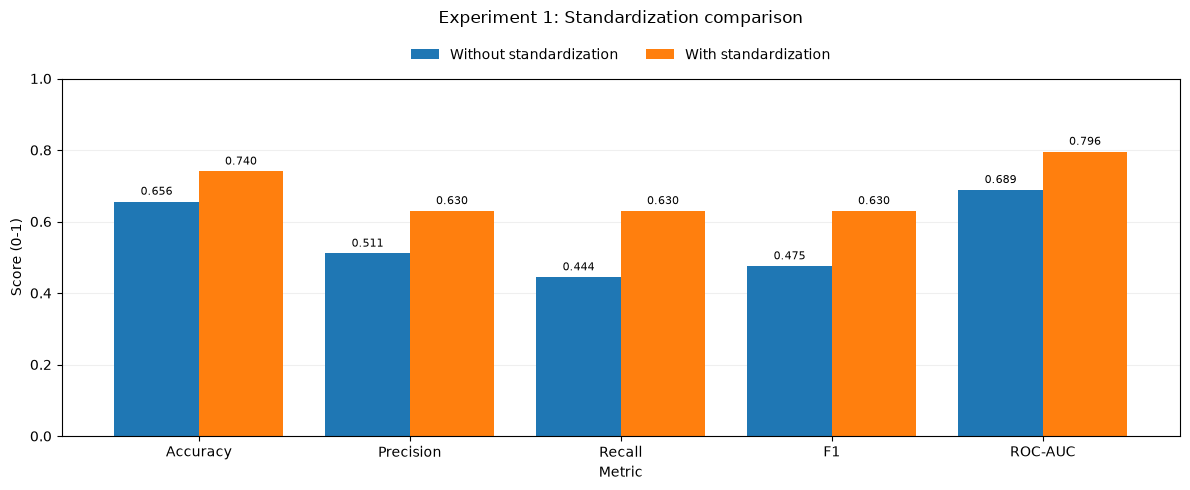

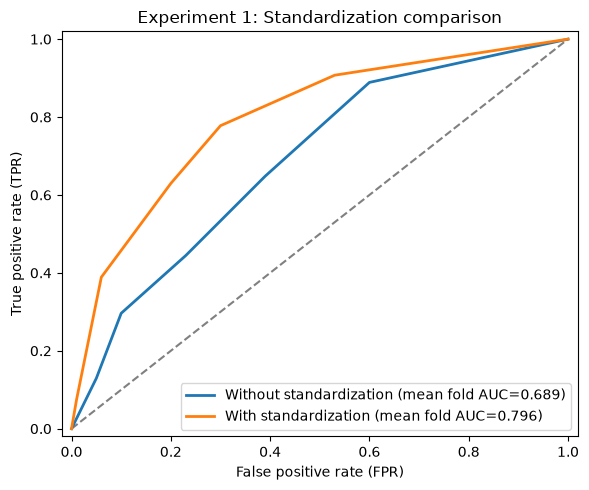

In [10]:
def experiment1(standardize):
    """Compare standardization using diabetes, k-NN, and a fixed split.

    :param standardize: Whether to standardize numeric features.
    :return: A one-item Result list for the percentage-split evaluation.
    """
    return evaluate_classifier(
        diabetes, KNN, [(diabetes_train, diabetes_test)], standardize,
    )

# Run both preprocessing configurations using the same training and test samples.
# Each result list contains one Result object.
r_without_list = experiment1(False)
r_with_list = experiment1(True)

# Output 1: comparison table for the five metrics.
# Use the shared per-fold averaging approach; with one fold, the mean is that fold's value.
metrics_without = pd.DataFrame(
    [r.get_metrics() for r in r_without_list]
).mean()

metrics_with = pd.DataFrame(
    [r.get_metrics() for r in r_with_list]
).mean()

# Compare the configurations and add a difference row: with minus without standardization.
comparison = pd.DataFrame({
    'With standardization': metrics_with,
    'Without standardization': metrics_without,
}).T

comparison.loc['Difference'] = (
    comparison.loc['With standardization'] - comparison.loc['Without standardization']
)
display(comparison)

# Output 2: confusion-matrix comparison table.
# Sum confusion matrices within each configuration; here each has one matrix.
cm_without = np.sum(
    [r.get_confusion_matrix() for r in r_without_list],
    axis=0,
)
cm_with = np.sum(
    [r.get_confusion_matrix() for r in r_with_list],
    axis=0,
)

# Flatten [[TP, FN], [FP, TN]] into a row to compare the counts.
cm_comparison = pd.DataFrame(
    [cm_with.ravel(), cm_without.ravel()],
    index=['With standardization', 'Without standardization'],
    columns=['TP', 'FN', 'FP', 'TN'],
)

cm_comparison.loc['Difference'] = (
    cm_comparison.loc['With standardization'] - cm_comparison.loc['Without standardization']
)

display(cm_comparison)

# Output 3: plot actual metric values, without then with standardization; keep differences in the table.
plot_metrics_comparison(
    comparison.loc[['Without standardization', 'With standardization']].set_axis(['Without standardization', 'With standardization']),
    title='Experiment 1: Standardization comparison',
)

# Output 4: plot the two ROC curves on the same axes.
# Each configuration has one fold, so each curve represents its test predictions.
fig, ax = plt.subplots(figsize=(6, 5))
roc_group = [
    ('Without standardization', r_without_list, 'tab:blue'),
    ('With standardization', r_with_list, 'tab:orange'),
]
plot_roc_comparison(
    ax,
    roc_group,
    title='Experiment 1: Standardization comparison',
)

plt.tight_layout()
plt.show()

### 4.3 Results and Conclusions

The **metric comparison table** shows that standardization increases accuracy from 65.58% to 74.03% and F1 from 0.4752 to 0.6296.

The **confusion-matrix comparison table** shows that false negatives (FN) decrease from 30 to 20 and false positives (FP) decrease from 23 to 20.

In the **metric comparison bar chart**, the **orange bars** for the standardized configuration are **higher** than the **blue bars** for the unstandardized configuration on all five metrics, consistent with the table.

In the **ROC comparison plot**, the orange curve for the **standardized** configuration is generally closer to the upper-left corner. ROC-AUC increases from 0.6886 to 0.7956.

Together, these outputs indicate that standardization **improves** k-NN classification performance under the settings of this experiment.


## 5. Experiment 2: Four Classifiers on Two Datasets

### 5.1 Objectives and Settings

Experiment 1 examined standardization. This experiment **compares four classifiers** and asks:

- **Which classifier performs better overall?**
- **How do the results differ between percentage-split evaluation and 10-fold cross-validation?**

Fixed settings:

- **Preprocessing:** Mean imputation + one-hot encoding + standardization.

There are three experimental factors:

- **Datasets × 2:** diabetes and heart-statlog.
- **Classifiers × 4:** Logistic regression, decision tree, random forest, and k-NN.
- **Evaluation protocols × 2:** Stratified percentage split and stratified 10-fold cross-validation.

The combinations of classifier, dataset, and evaluation protocol give **4 × 2 × 2 = 16 experimental configurations**. Each configuration is evaluated once, producing **16 result sets**. Here, a result set is the collection of `Result` objects returned by one evaluation:

- **Percentage split:** One `Result`; its five metrics are used directly.
- **10-fold cross-validation:** Ten `Result` objects; each metric is calculated per fold and then averaged over the ten folds.

```mermaid
flowchart LR
    A["Classifier: choose 1 of 4<br/>Logistic regression<br/>Decision tree<br/>Random forest<br/>k-NN"] --> B["Dataset: choose 1 of 2<br/>diabetes<br/>heart-statlog"]
    B --> C["Percentage split"]
    B --> D["10-fold cross-validation"]
    C --> E["1 Result object<br/>per result set"]
    D --> F["10 Result objects<br/>per result set"]
    E --> G["Five metrics<br/>ROC curve"]
    F --> I["Summarize across folds:<br/>average metrics and align ROC curves"]
    I --> H["Five mean metrics<br/>Mean ROC curve"]
```

### 5.2 Experimental Outputs

The outputs are organized into two comparisons.

#### 5.2.1 Evaluation Protocol Comparison

For each classifier on each dataset, compare the two evaluation protocols using:

- **Metric comparison tables:** 8 in total.
- **Metric comparison bar charts:** 8 in total.
- **ROC comparison plots:** 8 in total.

#### 5.2.2 Classifier Comparison

For each dataset, summarize the **10-fold cross-validation** results of the four classifiers using:

- **Metric summary tables:** 2 in total.
- **Metric summary bar charts:** 2 in total.
- **ROC summary plots:** 2 in total.


#### Logistic regression: pima_diabetes

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.6948,0.5778,0.4815,0.5253,0.8122
10-fold CV,0.7668,0.7263,0.5563,0.6226,0.8361
Difference,0.0720,0.1485,0.0748,0.0974,0.0239


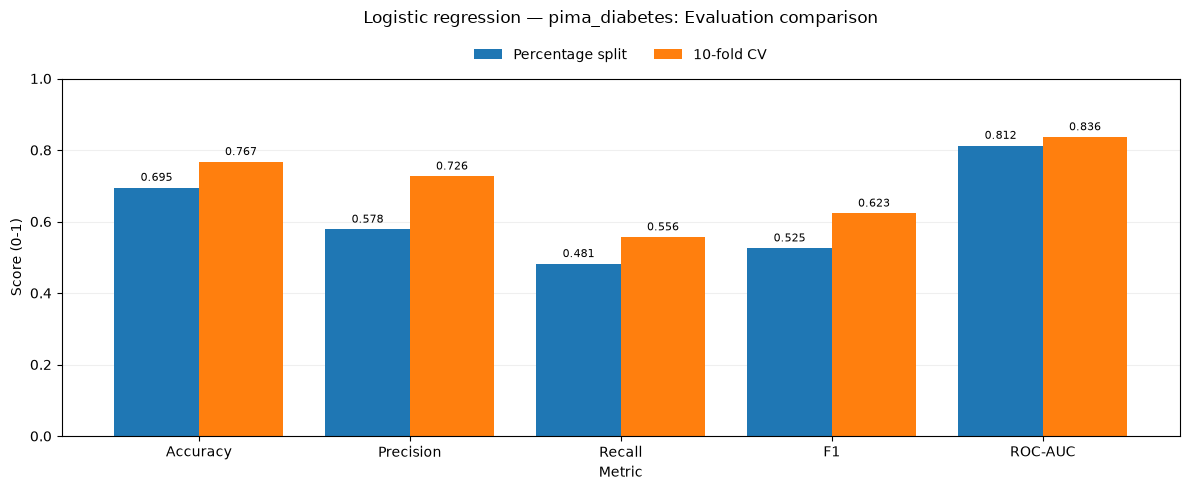

#### Logistic regression: heart-statlog

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.8704,0.8148,0.9167,0.8627,0.8986
10-fold CV,0.8444,0.8581,0.7917,0.8184,0.9106
Difference,-0.0259,0.0433,-0.1250,-0.0443,0.0119


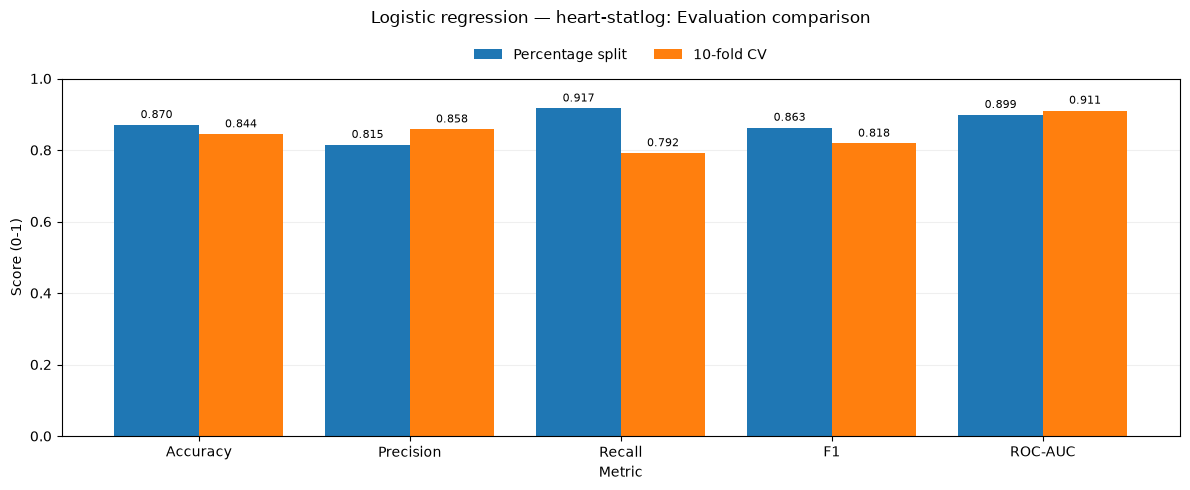

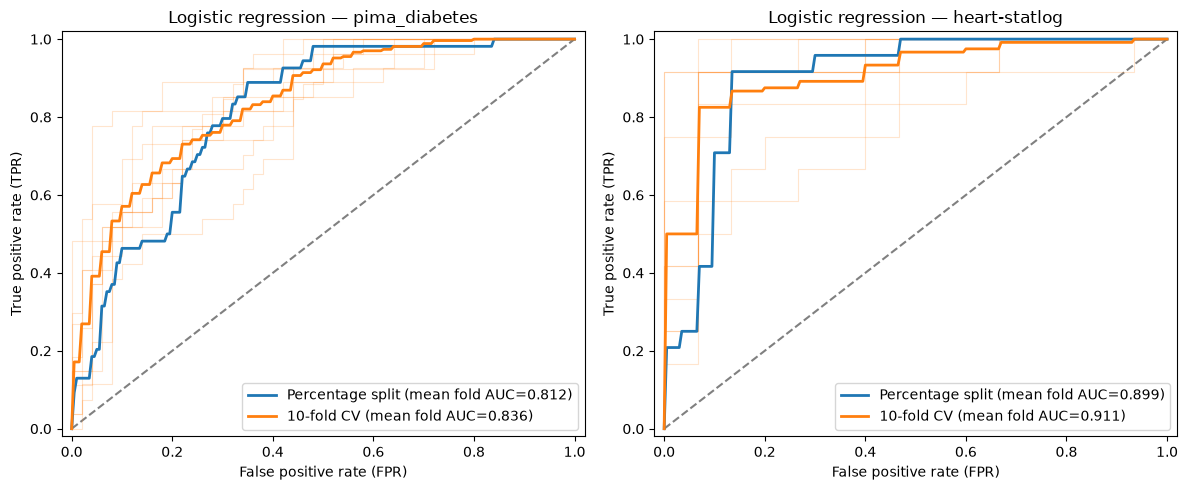

#### Decision tree: pima_diabetes

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.6688,0.5333,0.4444,0.4848,0.6172
10-fold CV,0.6964,0.5648,0.5926,0.5758,0.6723
Difference,0.0275,0.0315,0.1481,0.0910,0.0551


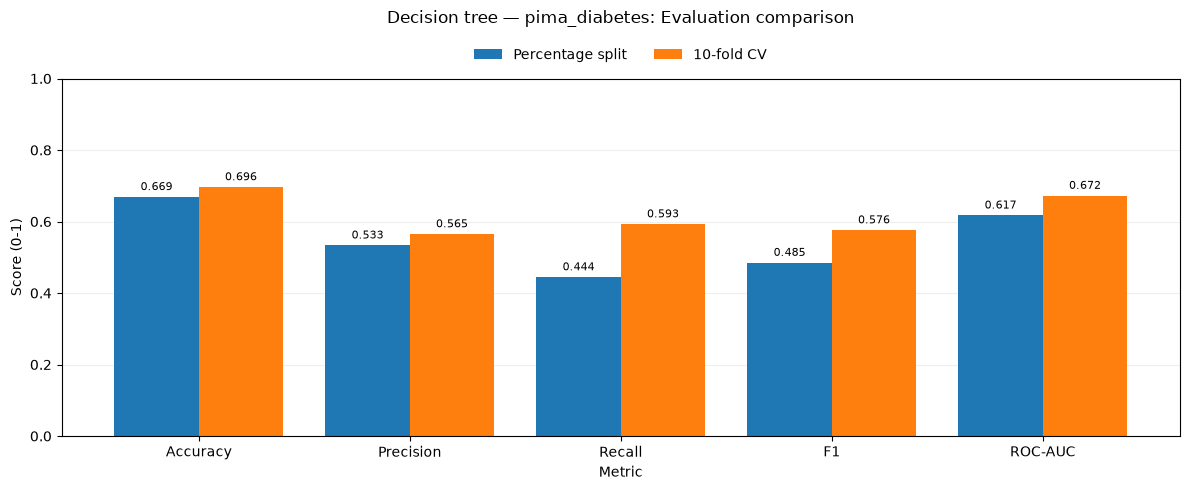

#### Decision tree: heart-statlog

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.7778,0.7308,0.7917,0.7600,0.7792
10-fold CV,0.7407,0.7214,0.7083,0.7076,0.7375
Difference,-0.0370,-0.0094,-0.0833,-0.0524,-0.0417


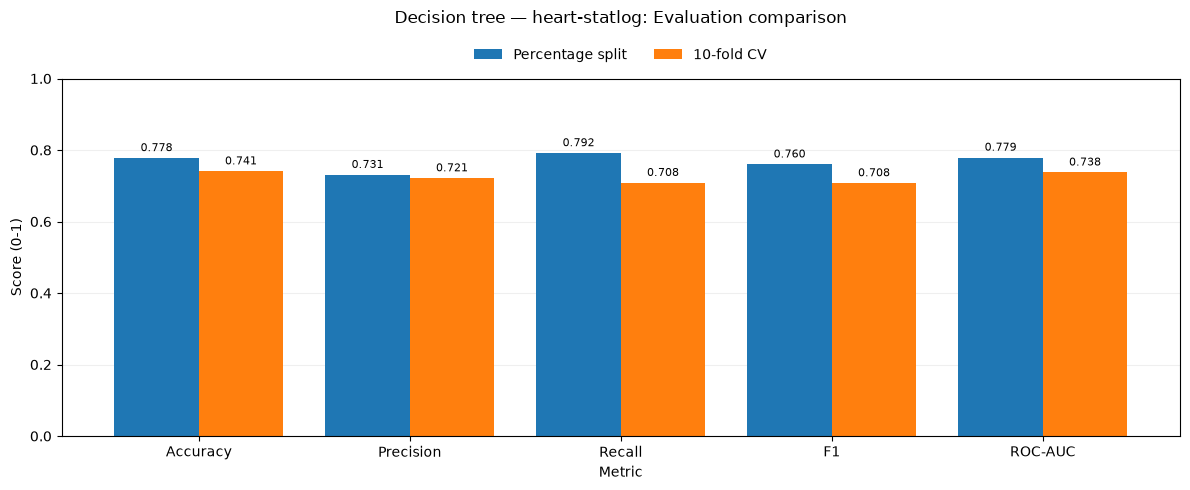

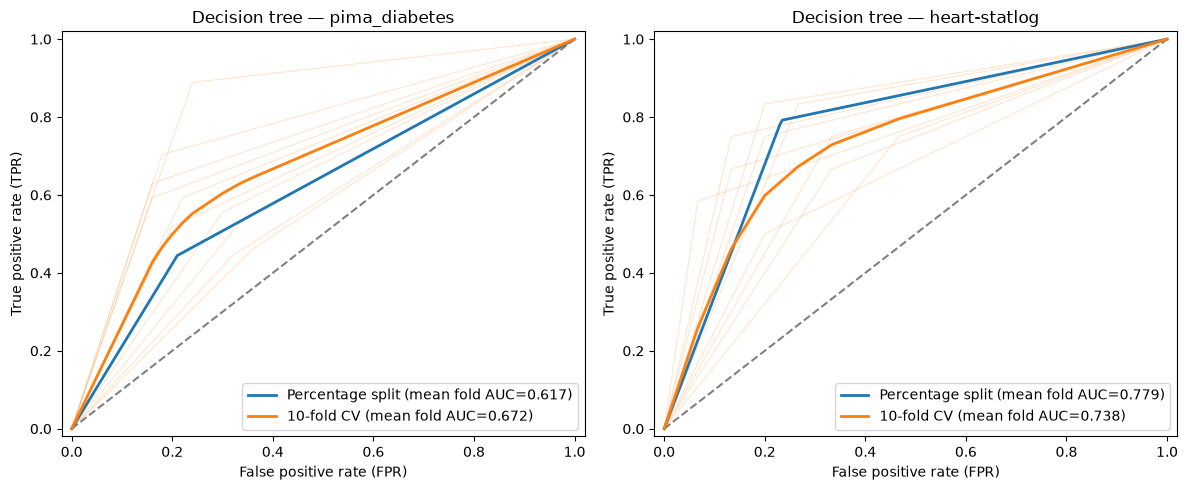

#### Random forest: pima_diabetes

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.7792,0.7083,0.6296,0.6667,0.8160
10-fold CV,0.7538,0.6683,0.6006,0.6296,0.8259
Difference,-0.0255,-0.0400,-0.0291,-0.0371,0.0099


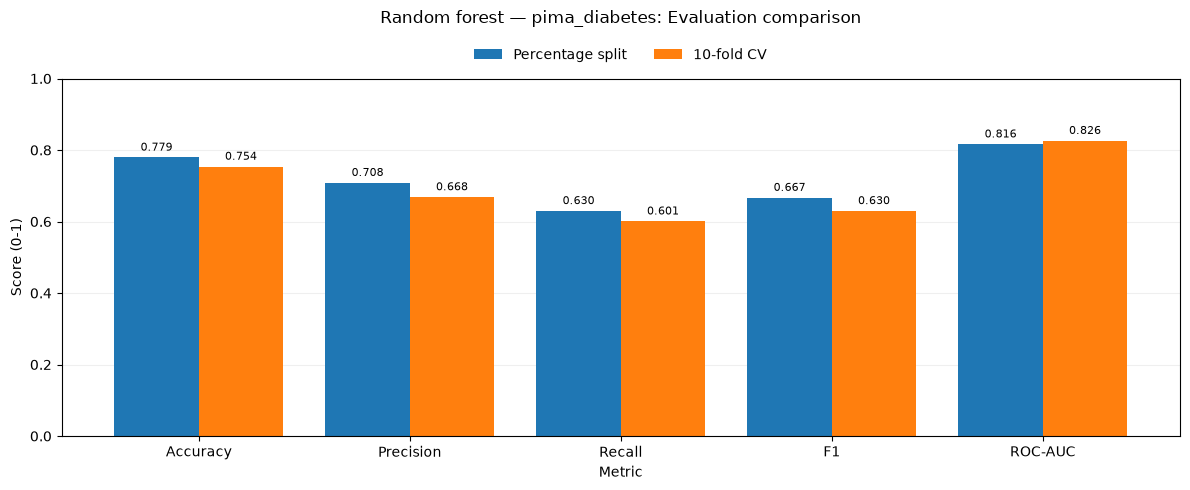

#### Random forest: heart-statlog

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.8148,0.7692,0.8333,0.8000,0.8847
10-fold CV,0.8111,0.8178,0.7583,0.7809,0.8786
Difference,-0.0037,0.0486,-0.0750,-0.0191,-0.0061


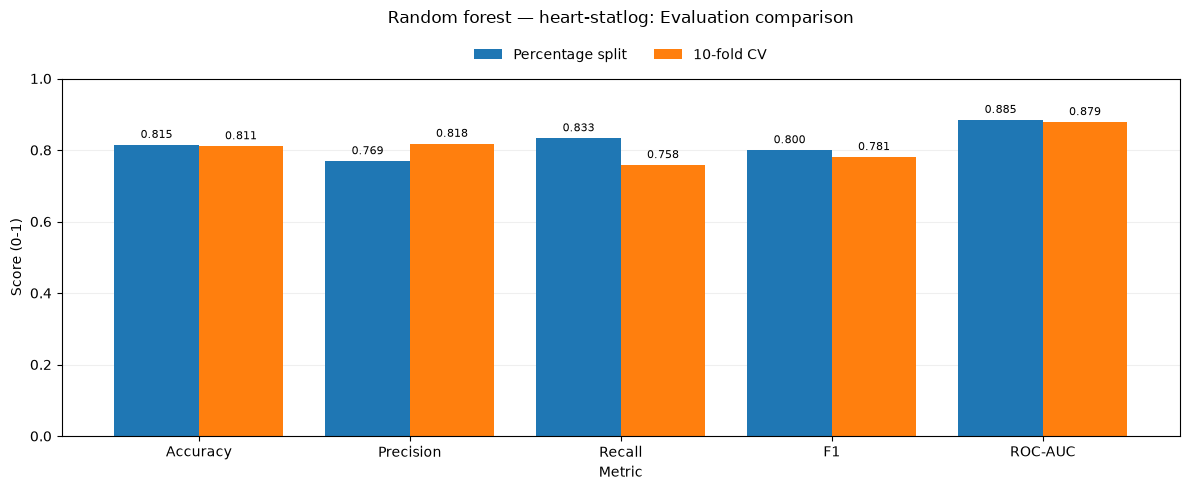

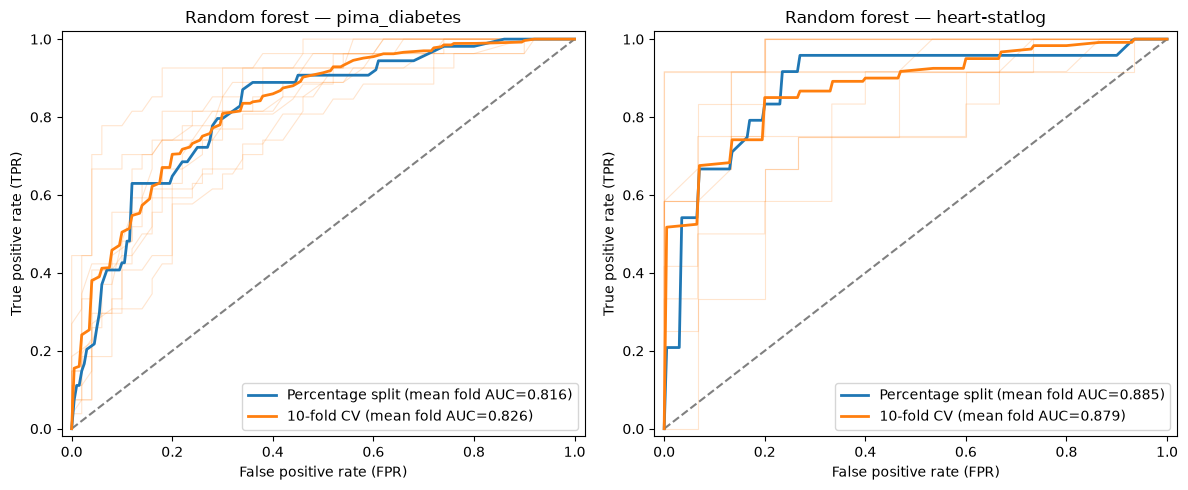

#### k-NN: pima_diabetes

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.7403,0.6296,0.6296,0.6296,0.7956
10-fold CV,0.7524,0.6548,0.6264,0.6389,0.7967
Difference,0.0122,0.0252,-0.0033,0.0092,0.0010


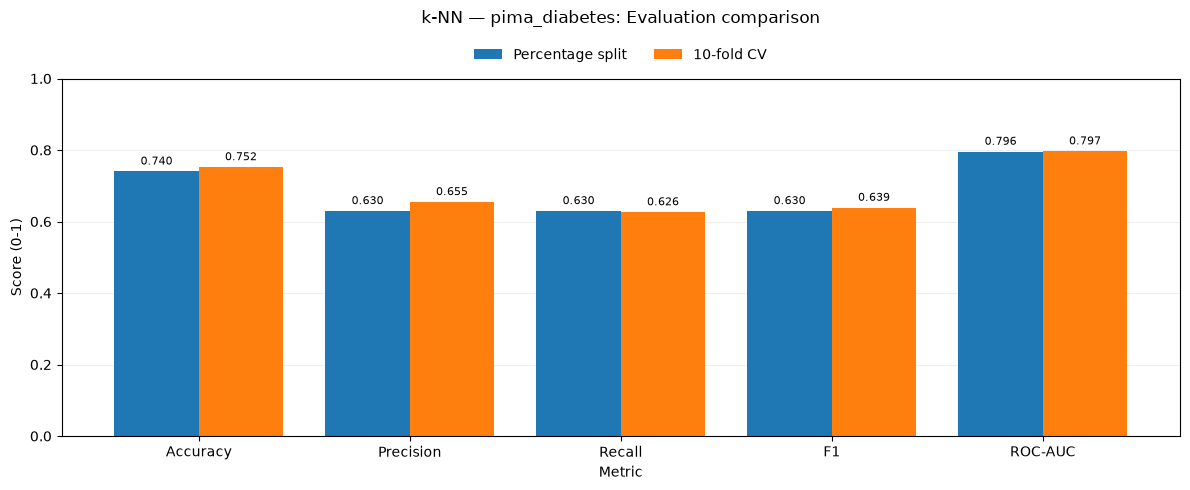

#### k-NN: heart-statlog

,Accuracy,Precision,Recall,F1,ROC-AUC
Percentage split,0.8333,0.7586,0.9167,0.8302,0.8826
10-fold CV,0.8222,0.8153,0.7833,0.7936,0.8792
Difference,-0.0111,0.0567,-0.1333,-0.0366,-0.0035


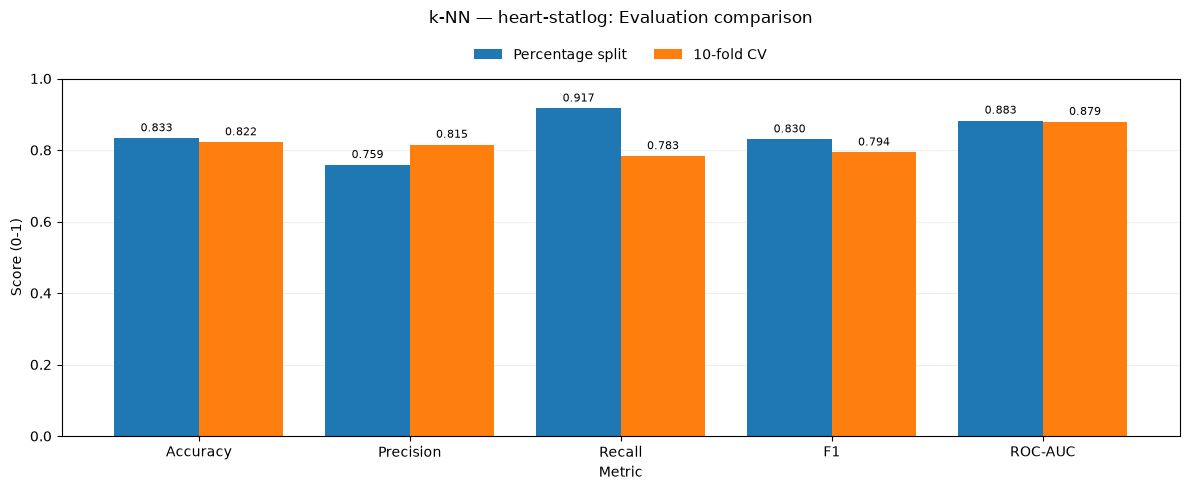

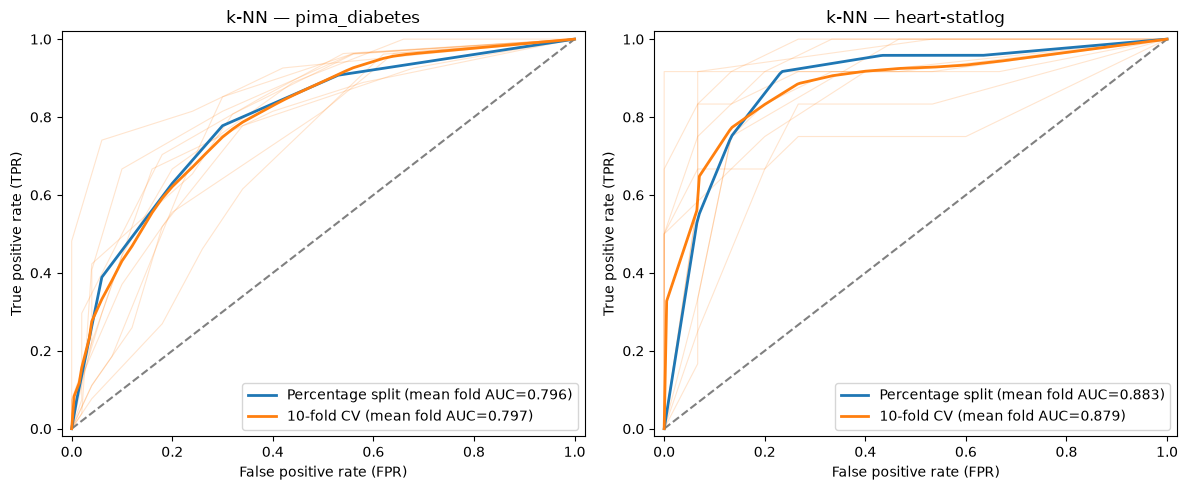

#### pima_diabetes: 10-fold CV metric means for four classifiers

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic regression,0.7668,0.7263,0.5563,0.6226,0.8361
Decision tree,0.6964,0.5648,0.5926,0.5758,0.6723
Random forest,0.7538,0.6683,0.6006,0.6296,0.8259
k-NN,0.7524,0.6548,0.6264,0.6389,0.7967


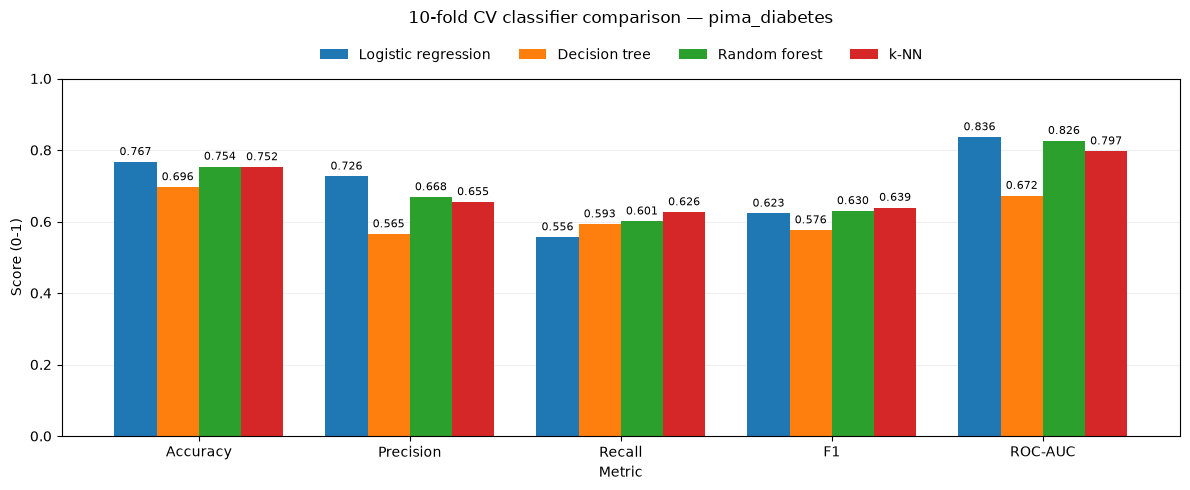

#### heart-statlog: 10-fold CV metric means for four classifiers

,Accuracy,Precision,Recall,F1,ROC-AUC
Logistic regression,0.8444,0.8581,0.7917,0.8184,0.9106
Decision tree,0.7407,0.7214,0.7083,0.7076,0.7375
Random forest,0.8111,0.8178,0.7583,0.7809,0.8786
k-NN,0.8222,0.8153,0.7833,0.7936,0.8792


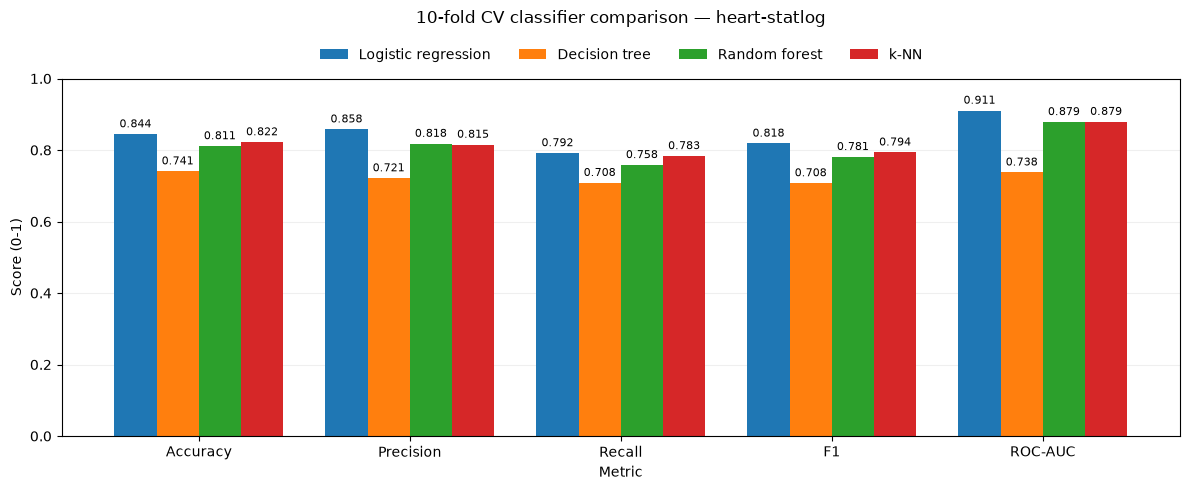

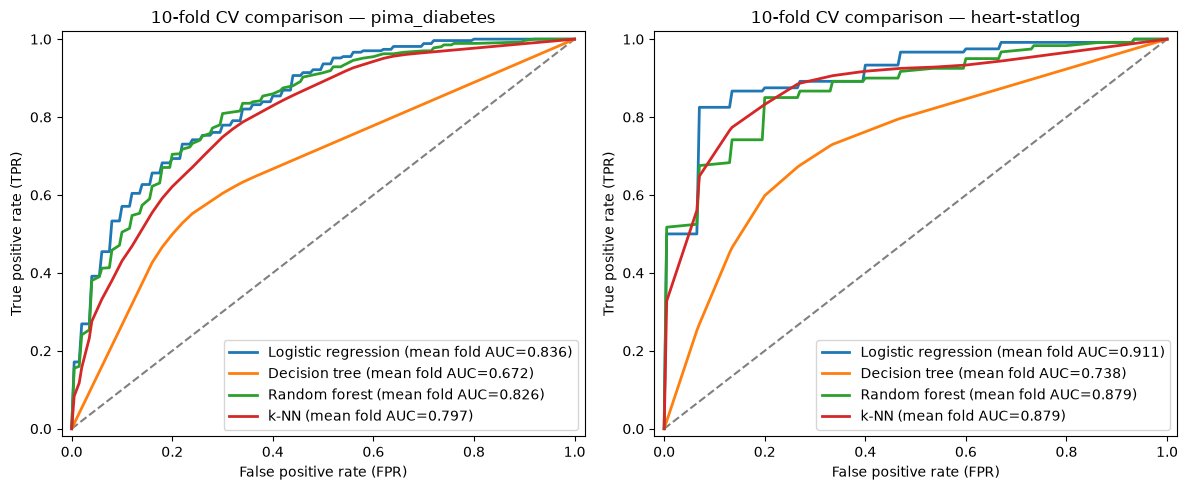

In [11]:
def experiment2(classifier, dataset, folds):
    """Evaluate one classifier/dataset/protocol configuration with standardization.

    :param classifier: Classifier template to evaluate.
    :param dataset: Dataset providing features, labels, and feature types.
    :param folds: One training/test index pair for percentage split or ten for CV.
    :return: Result list containing one object per split.
    """
    return evaluate_classifier(dataset, classifier, folds, standardize=True)

# Store all 16 result sets, keyed by classifier name, dataset name, and evaluation protocol.
results2 = {}
# Store 10-fold metric means as {dataset: {classifier: metrics}} for the summary comparison.
cv_metrics = {DIABETES: {}, HEART_STATLOG: {}}

classifiers = [
    ('Logistic regression', LOGISTIC),
    ('Decision tree', TREE),
    ('Random forest', FOREST),
    ('k-NN', KNN),
]

# Evaluate each classifier on both datasets under both evaluation protocols.
for model_name, classifier in classifiers:
    # Keep this classifier's results for both datasets for the ROC comparison plots.
    model_results = []

    # Use the saved row indices: one pair for percentage split and ten pairs for CV.
    for dataset, percentage_split, folds in [
        (diabetes, [(diabetes_train, diabetes_test)], diabetes_folds),
        (heart, [(heart_train, heart_test)], heart_folds),
    ]:
        results_ps = experiment2(classifier, dataset, percentage_split)
        results_cv = experiment2(classifier, dataset, folds)
        results2[model_name, dataset.name, 'split'] = results_ps
        results2[model_name, dataset.name, 'cv10'] = results_cv
        model_results.append((dataset.name, results_ps, results_cv))

        # Calculate five metrics for each protocol: use the single-fold values or average across folds.
        # Save the CV means to compare classifiers under the same evaluation protocol.
        metrics_ps = pd.DataFrame([r.get_metrics() for r in results_ps]).mean()
        metrics_cv = pd.DataFrame([r.get_metrics() for r in results_cv]).mean()
        cv_metrics[dataset.name][model_name] = metrics_cv

        # Output 1: metric tables and bar charts; differences are 10-fold CV minus percentage split.
        metrics_comparison = pd.DataFrame({
            'Percentage split': metrics_ps,
            '10-fold CV': metrics_cv,
        }).T
        metrics_comparison.loc['Difference'] = (
            metrics_comparison.loc['10-fold CV'] - metrics_comparison.loc['Percentage split']
        )
        display(Markdown(f'#### {model_name}: {dataset.name}'))
        display(metrics_comparison.round(4))
        # Plot only the first two rows of actual values; retain the difference row in the table.
        plot_metrics_comparison(
            metrics_comparison.iloc[:2].set_axis(['Percentage split', '10-fold CV']),
            title=f'{model_name} — {dataset.name}: Evaluation comparison',
        )

    # Output 2: compare this classifier's ROC curves, with one dataset per panel.
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, (dataset_name, results_ps, results_cv) in zip(axes, model_results):
        # Show individual-fold curves as pale lines alongside the mean ROC curve.
        roc_group = [
            ('Percentage split', results_ps, 'tab:blue'),
            ('10-fold CV', results_cv, 'tab:orange', True),
        ]
        plot_roc_comparison(
            ax,
            roc_group,
            title=f'{model_name} — {dataset_name}',
        )

    plt.tight_layout()
    plt.show()

# Output 3: summarize the four classifiers using 10-fold metric means for each dataset.
# Summary rows are classifiers; columns are organized as dataset then metric.
exp2_summary = pd.concat({
    dataset_name: pd.DataFrame(metrics).T
    for dataset_name, metrics in cv_metrics.items()
}, axis=1)
for dataset_name in [DIABETES, HEART_STATLOG]:
    display(Markdown(f'#### {dataset_name}: 10-fold CV metric means for four classifiers'))
    display(exp2_summary[dataset_name].round(4))
    plot_metrics_comparison(
        exp2_summary[dataset_name],
        title=f'10-fold CV classifier comparison — {dataset_name}',
    )

# Output 4: compare the classifiers' mean CV ROC curves for each dataset.
# With show_folds=False, show one mean curve per classifier without individual-fold curves.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, dataset_name in zip(axes, [DIABETES, HEART_STATLOG]):
    roc_group = [
        (model_name, results2[model_name, dataset_name, 'cv10'], f'C{i}', False)
        for i, (model_name, _) in enumerate(classifiers)
    ]
    plot_roc_comparison(
        ax,
        roc_group,
        title=f'10-fold CV comparison — {dataset_name}',
    )

plt.tight_layout()
plt.show()


### 5.3 Results and Conclusions

#### 5.3.1 Reading the ROC Plots

- **Thick colored lines:** Percentage-split ROC curves or mean ROC curves from 10-fold cross-validation.
- **Thin, pale lines:** Individual-fold ROC curves from 10-fold cross-validation.

#### 5.3.2 How Do the Two Evaluation Protocols Differ?

##### Observations from the Bar Charts

We describe one protocol as scoring higher across the board only when **all five metric values are higher**. The **comparison bar charts** show:

- **diabetes:** **10-fold CV** on Logistic regression and decision tree scores higher. For the other classifiers, the comparison is mixed.
- **heart-statlog:** **Percentage-split evaluation** on Decision tree scores higher on all five metrics. For the other classifiers, the comparison is mixed.

##### Observations from the ROC Plots

- **Between protocols:** The thick blue and orange curves are often close or cross. Neither protocol consistently produces a curve closer to the upper-left corner. The differences are more visible for decision tree: the orange curve is higher on diabetes, while the blue curve is higher on heart-statlog.
- **Across folds:** The thin orange curves vary, showing that the same classifier performs differently with different training and test samples.

##### Conclusion

The two protocols yield different performance estimates. Neither produces higher values for every classifier and dataset.

#### 5.3.3 Which Classifier Performs Better Overall?

All classifier comparisons below use the 10-fold cross-validation results.

##### Observations from the Bar Charts

- **diabetes:** Logistic regression has the highest accuracy, precision, and ROC-AUC; k-NN has the highest recall and F1. No classifier leads on all five metrics.
- **heart-statlog:** Logistic regression has the highest values on all five metrics.
- **Across both datasets:** Random forest scores higher than decision tree on all five metrics.

##### Observations from the ROC Plots

The ROC curves for logistic regression, random forest, and k-NN are relatively close on both datasets. Decision tree generally has a lower curve, with a more visible gap.

##### Conclusion

Logistic regression performs slightly better overall across the two datasets, although its advantage over random forest and k-NN is modest. Decision tree has the lowest values on most metrics and performs weakest overall in this comparison.


## 6. Experiment 3: Clustering Structure and Class-Label Distributions in diabetes

### 6.1 Objectives and Settings

The first two experiments predict disease labels from clinical measurements. This experiment takes a different approach: **cluster samples using their features without using disease labels**. It asks:

- **Which candidate number of clusters is more suitable?**
- **What characterizes each cluster, and how do the clusters differ?**
- **Do the clusters correspond to the negative and positive disease classes?**

Fixed settings:

- **Dataset:** diabetes.
- **Clustering method:** K-means.
- **Preprocessing:** Mean imputation + one-hot encoding + standardization.

There is one experimental variable:

- **Number of clusters, `k`:** 2, 3, 4, 5, and 6.

The 5 settings produce **5 `ClusterResult` objects**. Each stores the number of clusters, the cluster assignment of every sample, and the mean silhouette score.

Silhouette coefficients range from −1 to 1. A higher mean silhouette score generally indicates more distinct clusters. We compare the five settings, select the one with the highest score, and examine its cluster profiles.

### 6.2 Experimental Outputs

The outputs are organized into three comparisons.

#### 6.2.1 Number of Clusters

Compare the mean silhouette scores for the five candidate values of `k` using:

- **1 silhouette-score comparison table.**
- **1 silhouette-score comparison line chart.**

#### 6.2.2 Cluster Feature Profiles

Use the setting with the highest mean silhouette score and compare cluster feature means in their original units:

- **1 cluster feature-mean table.**
- **8 feature-mean bar charts**, one per feature, arranged on one figure.

#### 6.2.3 Cluster Class-Label Distributions

For the selected setting, examine the class-label distribution within each cluster and compare its positive-class proportion with the full dataset:

- **1 cluster class-label distribution table.**
- **1 bar chart of cluster positive-class proportions.**


In [12]:
X_cluster = make_preprocessor(
    diabetes, standardize=True,
).fit_transform(diabetes.X)

k,Silhouette score
2,0.1965
3,0.1950
4,0.1832
5,0.1774
6,0.1667


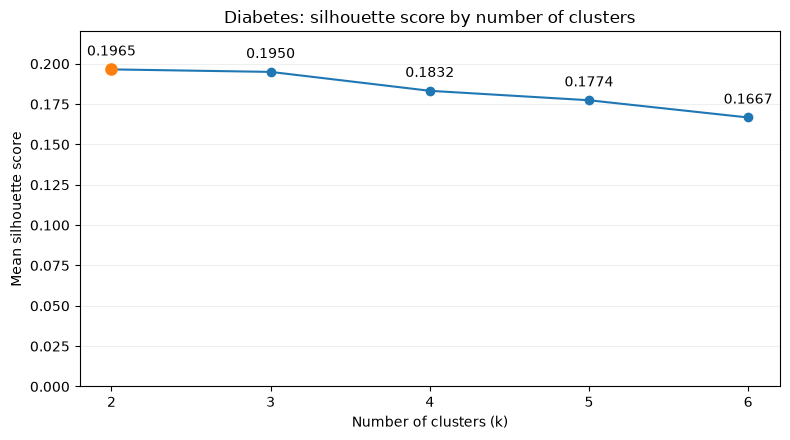

Selected **k=2**, mean silhouette score: **0.1965**.

#### Cluster feature means (original units)

,preg,plas,pres,skin,insu,mass,pedi,age
0,2.22,107.92,66.57,25.20,111.08,30.14,0.44,26.44
1,5.77,137.94,79.11,34.75,224.85,35.17,0.51,41.28


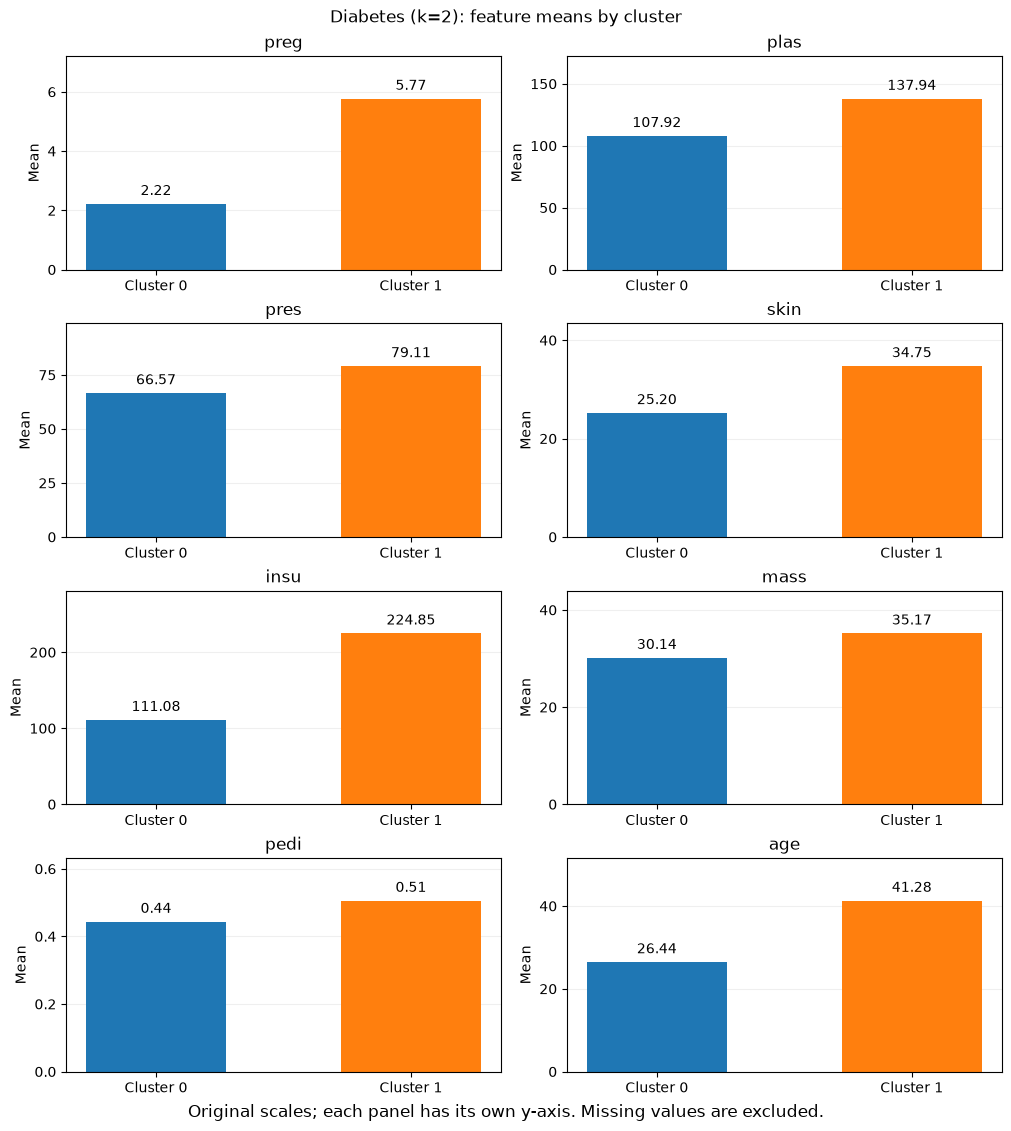

#### Cluster disease-label distributions

,Total,Negative,Positive,Positive proportion
0,416,344,72,17.3%
1,352,156,196,55.7%
Overall,768,500,268,34.9%


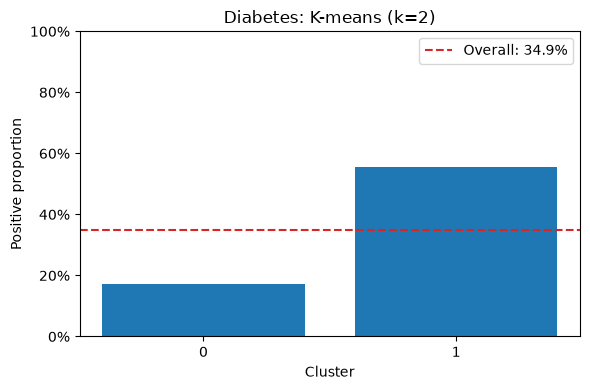

In [13]:
class ClusterResult:
    """Store one clustering result and provide cluster feature and label summaries.

    :ivar k: Number of clusters.
    :ivar clusters: Cluster assignments in input-sample order.
    :ivar silhouette: Mean silhouette score for this setting.
    """
    def __init__(self, k, clusters, silhouette):
        """Store the clustering result for one value of k.

        :param k: Number of clusters.
        :param clusters: Cluster assignments in input-sample order.
        :param silhouette: Mean silhouette score for these assignments.
        :return: None; stores the result as instance attributes.
        """
        self.k = k
        self.clusters = clusters
        self.silhouette = silhouette

    def get_feature_means(self, dataset):
        """Calculate numeric feature means per cluster in original units, excluding NaN.

        :param dataset: Dataset in the clustering sample order, with original-scale features.
        :return: DataFrame with clusters as rows and numeric features as columns.
        """
        return dataset.X[dataset.numeric].groupby(self.clusters).mean()

    def get_label_distribution(self, dataset):
        """Summarize disease labels within each cluster after clustering.

        :param dataset: Dataset in the clustering sample order; True denotes positive.
        :return: DataFrame with cluster sample counts, negative and positive counts,
            and the positive-class proportion.
        """
        table = dataset.y.groupby(self.clusters).agg(Total='size', Positive='sum')
        table['Negative'] = table['Total'] - table['Positive']
        table['Positive proportion'] = table['Positive'] / table['Total']
        return table[['Total', 'Negative', 'Positive', 'Positive proportion']]



def plot_silhouette_comparison(table, title):
    """Compare mean silhouette scores across k and highlight the highest score.

    :param table: DataFrame with k and Silhouette score columns, one row per setting.
    :param title: Chart title.
    :return: None; creates and displays a line chart.
    """
    fig, ax = plt.subplots(figsize=(8, 4.5))
    ax.plot(table['k'], table['Silhouette score'], marker='o', color='C0')
    # Highlight the highest-scoring candidate in orange; retain the other points for comparison.
    best = table.loc[table['Silhouette score'].idxmax()]
    ax.scatter(best['k'], best['Silhouette score'], color='C1', s=65, zorder=3)
    for k, score in table.itertuples(index=False, name=None):
        ax.annotate(
            f'{score:.4f}', (k, score), xytext=(0, 10),
            textcoords='offset points', ha='center',
        )
    ax.set(
        title=title, xlabel='Number of clusters (k)',
        ylabel='Mean silhouette score', xticks=table['k'],
        ylim=(0, table['Silhouette score'].max() * 1.12),
    )
    ax.grid(axis='y', alpha=0.2)
    plt.tight_layout()
    plt.show()


def plot_cluster_feature_means(feature_means, title):
    """Plot feature means per cluster with a separate y-axis for each feature.

    :param feature_means: Original-scale feature means; rows are clusters, columns are features.
    :param title: Figure title.
    :return: None; creates and displays the feature-mean comparison figure.
    """
    n_rows = (len(feature_means.columns) + 1) // 2
    fig, axes = plt.subplots(
        n_rows, 2, figsize=(10, 2.8 * n_rows),
        squeeze=False, layout='constrained',
    )
    clusters = [f'Cluster {cluster}' for cluster in feature_means.index]
    # Use the same color for a cluster across all feature plots.
    colors = [f'C{i}' for i in range(len(feature_means))]
    # Features have different units and ranges, so use separate y-axis limits.
    for ax, feature in zip(axes.flat, feature_means.columns):
        values = feature_means[feature]
        bars = ax.bar(clusters, values, color=colors, width=0.55)
        ax.bar_label(bars, fmt='%.2f', padding=4)
        ax.set(title=feature, ylabel='Mean', ylim=(0, values.max() * 1.25))
        ax.locator_params(axis='y', nbins=4)
        ax.set_axisbelow(True)
        ax.grid(axis='y', alpha=0.2)
    # Hide unused subplots and add the figure title and explanatory label.
    for ax in axes.flat[len(feature_means.columns):]:
        ax.set_visible(False)
    fig.suptitle(title)
    fig.supxlabel(
        'Original scales; each panel has its own y-axis. Missing values are excluded.'
    )
    plt.show()


def experiment3(k):
    """Cluster the full preprocessed diabetes data for one value of k.

    :param k: Number of K-means clusters.
    :return: ClusterResult storing k, sample cluster assignments, and mean silhouette score.
    """
    model = KMeans(
        n_clusters=k,
        random_state=SEED,
        n_init=20,
    )

    # Cluster using clinical features only, then calculate the silhouette score from features and assignments.
    clusters = model.fit_predict(X_cluster)
    silhouette = silhouette_score(X_cluster, clusters)

    return ClusterResult(k, clusters, silhouette)

# Try five cluster counts using the same preprocessed X_cluster; save one ClusterResult per setting.
results3 = [
    experiment3(k)
    for k in [2, 3, 4, 5, 6]
]

# Output 1: compare the five cluster counts using a silhouette-score table and line chart.
silhouette_table = pd.DataFrame([
    {'k': result.k, 'Silhouette score': result.silhouette}
    for result in results3
])

display(
    silhouette_table.style
    .hide(axis='index')
    .format({'Silhouette score': '{:.4f}'})
)
plot_silhouette_comparison(
    silhouette_table,
    title='Diabetes: silhouette score by number of clusters',
)

# Select the highest mean silhouette score; disease labels are not used for selection.
best_result = max(results3, key=lambda result: result.silhouette)

display(Markdown(
    f'Selected **k={best_result.k}**, '
    f'mean silhouette score: **{best_result.silhouette:.4f}**.'
))

# Output 2: feature-mean table and bar charts for the selected setting, in original units and excluding NaN.
feature_means = best_result.get_feature_means(diabetes)

display(Markdown('#### Cluster feature means (original units)'))
display(feature_means.round(2))
plot_cluster_feature_means(
    feature_means,
    title=f'Diabetes (k={best_result.k}): feature means by cluster',
)

# Output 3: examine disease labels only after clustering; show cluster sizes, class counts, and positive proportions.
label_distribution = best_result.get_label_distribution(diabetes)

# Add full-dataset statistics as a reference for the cluster positive-class proportions.
overall = pd.DataFrame({
    'Total': [len(diabetes.y)],
    'Negative': [(~diabetes.y).sum()],
    'Positive': [diabetes.y.sum()],
    'Positive proportion': [diabetes.y.mean()],
}, index=['Overall'])

label_table = pd.concat([label_distribution, overall])

display(Markdown('#### Cluster disease-label distributions'))
display(label_table.style.format({'Positive proportion': '{:.1%}'}))

# Each bar shows the positive-class proportion within one cluster.
fig, ax = plt.subplots(figsize=(6, 4))

ax.bar(
    label_distribution.index.astype(str),
    label_distribution['Positive proportion'],
    color='tab:blue',
)

# The red dashed line shows the positive-class proportion in the full dataset.
overall_ratio = diabetes.y.mean()
ax.axhline(
    overall_ratio,
    color='tab:red',
    linestyle='--',
    label=f'Overall: {overall_ratio:.1%}',
)

ax.set(
    title=f'Diabetes: K-means (k={best_result.k})',
    xlabel='Cluster',
    ylabel='Positive proportion',
    ylim=(0, 1),
)
ax.yaxis.set_major_formatter(PercentFormatter(xmax=1))
ax.legend()

plt.tight_layout()
plt.show()

### 6.3 Results and Conclusions

#### 6.3.1 Which Candidate Number of Clusters Is More Suitable?

##### Observations from the Line Chart

- **Highest score:** `k=2` has the highest mean silhouette score, 0.1965. The score for `k=3` is 0.1950, placing the two points at almost the same height.
- **Trend:** From `k=3` onward, the score decreases as more clusters are added. Even the highest score is only about 0.20, compared with a maximum possible silhouette coefficient of 1.

##### Conclusion

We select `k=2` because it has the highest score among the candidates, although the clusters are not well separated.

#### 6.3.2 What Characterizes Each Cluster?

##### Observations from the Feature-Mean Bar Charts

- **Cluster 0:** Lower means for all eight features, including lower mean age, glucose, and BMI.
- **Cluster 1:** Higher means for all eight features, including higher mean age, glucose, and BMI.

##### Conclusion

The two clusters differ in their average feature levels.

#### 6.3.3 Do the Clusters Correspond to Disease Classes?

##### Observations from the Label Distribution Table and Positive-Proportion Chart

- **Cluster 0:** The positive-class proportion is 17.3%, below the overall proportion of 34.9%. Most samples are negative.
- **Cluster 1:** The positive-class proportion is 55.7%, above the overall proportion of 34.9%. However, 44.3% of samples are still negative.

##### Conclusion

The positive-class proportions differ considerably, but both clusters contain positive and negative samples. The classes are more evenly mixed in cluster 1. The two clusters therefore cannot be identified directly with the negative and positive disease classes.

#### 6.3.4 Overall Conclusion

`k=2` has the highest mean silhouette score among the candidates. Its clusters differ in both feature means and positive-class proportions. However, separation is limited and both clusters contain both classes. K-means reveals some differences between groups of samples under this preprocessing scheme, but the clusters do not coincide with the disease classes.


## 7. Team Contributions

- **Member 1: HU Yining (3162495)**

  - **Assigned section:** Data description and exploratory analysis.

  - **Main tasks:**

    - Read and verify dataset descriptions, attributes, and labels.
    - Prepare the initial experimental plan.
    - Load the data and produce the summary table and feature distribution plots.
    - Identify and mark unrecorded missing values.
    - Analyze missing-value proportions and distributions before and after marking missing values.

  - **Workload share:** 20%.

- **Member 2: CHEN Sitao (3163293)**

  - **Assigned section:** Shared experimental methods.

  - **Main tasks:**

    - Generate and save shared data splits.
    - Define the shared preprocessing plan.
    - Design Result storage and implement evaluation metrics, confusion matrices, and ROC calculations.
    - Implement shared classification evaluation and plotting functions.

  - **Workload share:** 20%.

- **Member 3: QU Yide (3352662)**

  - **Assigned section:** Experiment 1: effect of standardization on k-NN.

  - **Main tasks:**

    - Compare configurations with and without standardization using the same split.
    - Prepare metric, confusion-matrix, and ROC comparison outputs.
    - Analyze the effect of standardization on classification performance.

  - **Workload share:** 20%.

- **Member 4: Wu Fei (3162926)**

  - **Assigned section:** Experiment 2: classifier and evaluation protocol comparisons.

  - **Main tasks:**

    - Evaluate all combinations of four classifiers, two datasets, and two evaluation protocols.
    - Prepare tables and plots comparing evaluation protocols and classifiers.
    - Analyze differences in results and variation across folds.

  - **Workload share:** 20%.

- **Member 5: MAI Zixi (3162873)**

  - **Assigned section:** Experiment 3: clustering structure and class-label distributions.

  - **Main tasks:**

    - Run K-means clustering and store results in ClusterResult objects.
    - Compare mean silhouette scores for five cluster counts and select a setting for analysis.
    - Analyze feature means and class-label distributions in the selected clusters.
    - Prepare the corresponding tables, plots, and conclusions.

  - **Workload share:** 20%.
